(social_security_depletion)=
```{raw} jupyter
<div id="qe-notebook-header" align="right" style="text-align:right;">
        <a href="https://quantecon.org/" title="quantecon.org">
                <img style="width:250px;display:inline;" width="250px" src="https://assets.quantecon.org/img/qe-menubar-logo.svg" alt="QuantEcon">
        </a>
</div>
```

# 社会保障信托基金耗竭

```{contents} Contents
:depth: 2
```

## 概述

社会保障受托人预测，老年和遗属保险信托基金的储备将在 $2032$ 年耗尽 {cite}`Trustees2026`。

该项目不能借贷。

除非国会采取行动，否则现行法律将按一个共同的因子 $\phi_t \le 1$ 削减每一份福利，使项目的现金流达到平衡：有权获得计划福利 $b^{sch}$ 的工人将领取 $\phi_t b^{sch}$。

我们称 $\phi_t$ 为**可支付因子**。

它不是某个人选定的政策参数。

它是一个均衡对象，因为它所缩放的数量取决于工人在展望它时所做的决策：

* 预期养老金较小的工人会工作更长时间并储蓄更多
* 在削减即将到来之前处于申领窗口内的工人有理由提前申领，因为此时福利仍全额支付
* 预期寿命更长的工人有理由延迟申领，因为等待的精算回报是由法规固定的

这些决策决定了应纳税工资总额和计划福利账单，而这恰恰是决定 $\phi_t$ 的两个数量。

本讲座研究这个不动点，遵循 {cite:t}`SargentShi2026` 的研究。

我们写出现行法律规定的账本，定义将一条可支付因子路径映射为另一条可支付因子路径的映射，并在一个定量世代交叠模型中计算其不动点，该模型包含

* 从 $20$ 岁到 $100$ 岁的生命周期，带有预测的死亡率
* 收入能力和工作偏好方面的永久异质性
* 法定福利公式、针对申领年龄的精算调整、应纳税上限，以及福利的征税
* 退休和福利申领作为**独立的**不可逆决策

练习随后将这套机制投入运用：探讨递减映射产生的振荡、提高完全退休年龄、保证支付计划福利需要花费多少成本，以及长期削减中有多少归因于预期寿命的上升。

有几个符号会反复出现，我们在此记录下来。

| 符号 | 含义 |
|---|---|
| $\phi_t$ | 可支付因子：实际支付的计划福利的共同比例 |
| $F_t$, $r^F$ | 信托基金余额及其计入的利率 |
| $N_t$ | 人口；其他所有总量均为人均值 |
| $\mathit{Pay}_t$, $B^{sch}_t$ | 人均应纳税工资总额和人均计划福利账单 |
| $\tau^{ss}$, $\kappa_b$, $\bar y$ | 工薪税率、所领福利的税率、应纳税上限 |
| $\mathrm{AIME}$, $\mathrm{PIA}$, $\psi$ | 收入记录、它购买的福利，以及该记录的累积速率 |
| $\mathrm{AF}(\chi)$, FRA, $\varsigma$ | 在申领年龄 $\chi$ 处的精算因子、完全退休年龄，以及福利规模因子 |
| $R$, $\chi$ | 工人的退休年龄和申领年龄 |
| $j$, $t$ | 年龄索引（$20$ 岁时为 $0$）和日历年份 |
| $e$, $h$ | 永久收入能力和工作偏好 |
| $\ell_j$, $\Omega$ | 从 $20$ 岁存活到 $20+j$ 岁的概率，以及 $\sum_j \beta^j\ell_j$ |
| $\tilde R$, $a_0$, $\mathcal W$ | 税后总回报率、手头资产，以及终生资源 |

本讲座是 {doc}`two_computation` 的姊妹篇，后者在 {cite:t}`huang1997two` 的模型中研究了从现收现付制过渡到完全积累制的两种方式。

而在本讲座中，没有人转向完全积累制：我们问的是现行法律自行运作会带来什么结果，以及阻止它需要什么成本。

另有两篇讲座提供了背景知识：{doc}`ak2` 介绍了 {cite:t}`auerbach1987dynamic` 世代交叠框架，{doc}`ak_aiyagari` 在其中加入了不可保险的特异性风险。

我们使用以下导入。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl  # i18n
FONTPATH = "fonts/SourceHanSerifSC-SemiBold.otf"  # i18n
mpl.font_manager.fontManager.addfont(FONTPATH)  # i18n
mpl.rcParams['font.family'] = ['Source Han Serif SC']  # i18n
from collections import namedtuple
from scipy.optimize import fsolve, brentq

## 制度

社会保障的账本由一个存量 $F_t$ 和两个流量组成。

该基金在其持有的特别发行国库证券上赚取一个管理利率 $r^F$，它收取工薪税，并支付福利。

记 $N_t$ 为人口，$\mathit{Pay}_t$ 为人均应纳税工资总额，$B^{sch}_t$ 为人均计划福利账单，账本演化为

```{math}
:label: ssd_fund
F_{t+1} = (1+r^F)F_t + N_t\left(\mathit{Rev}_t - \phi_t B^{sch}_t\right),
\qquad F_t \ge 0 ,
```

其中项目收入是工薪税加上项目支付福利时返还给项目的税收，

```{math}
:label: ssd_rev
\mathit{Rev}_t = \tau^{ss}\mathit{Pay}_t + \kappa_b \phi_t B^{sch}_t .
```

{eq}`ssd_fund` 中的约束 $F_t \ge 0$ 就是法律规定：该项目不得借贷。

正是这一点将 $\phi_t$ 压到一以下。

该项目支付其资源所能允许的最大共同比例的计划福利，

```{math}
:label: ssd_phi
\phi_t = \min\left\{1, \;
\frac{(1+r^F)F_t + N_t\tau^{ss}\mathit{Pay}_t}
     {N_t(1-\kappa_b)B^{sch}_t}\right\} .
```

分子是该项目可以动用的资源：它所结转的余额加上它所收取的工薪税。

分母是它所欠的款项，扣除返还给它的福利税。

我们将耗竭定义为基金首次为空的那一年，

$$
t^{dep} = \min\{t : F_t = 0\} ,
$$

我们称 $t^{dep}-1$ 为**首个短缺年**，即该项目支付其最后储备的那一年，也是 $\phi_t < 1$ 的第一年。

```{note}
受托人将"储备耗竭"的日期定为储备耗尽的那一年，这里即为首个短缺年。

因此，他们预测的 $2032$ 年就是我们的 $t^{dep}-1$，而整个福利被削减的第一年是 $2033$ 年。
```

从 $t^{dep}$ 开始，基金为空，{eq}`ssd_phi` 简化为一个现金流条件，

```{math}
:label: ssd_phiflow
\phi_t = \frac{\tau^{ss}\mathit{Pay}_t}{(1-\kappa_b)B^{sch}_t},
\qquad t \ge t^{dep} .
```

### 可支付因子是一个不动点

方程 {eq}`ssd_phiflow` 看起来像是 $\phi_t$ 的一个公式，但 $\mathit{Pay}_t$ 和 $B^{sch}_t$ 都是由工人在观察整个未来路径 $\{\phi_s\}$ 时所做的决策构建起来的。

设 $\Phi$ 为这样一个映射：它接受候选路径 $\{\phi_s\}_{s\ge 0}$，将其交给工人，收集他们最优决策所产生的应纳税工资总额和计划福利，运行账本 {eq}`ssd_fund`，并返回账本所暗含的可支付路径 {eq}`ssd_phi`。

均衡可支付路径是一个不动点，

```{math}
:label: ssd_fixedpoint
\{\phi_t\} = \Phi\big(\{\phi_t\}\big) .
```

```{important}
$\Phi$ 是一个**递减的**映射。

提高候选路径，福利就变得更有价值，于是工人更早申领、更早退休；应纳税工资总额下降，计划账单上升；{eq}`ssd_phi` 随后返回一个*更小*的数值。

因此，连续的猜测会围绕不动点交替变化，而不是从某一侧逐渐逼近。

交替变化是否会消失取决于工人反应的强度，{ref}`ssd_ex1` 找到了交替变化不会消失的日期：未经阻尼的迭代会稳定在一个二周期中，并停留在那里。

因此，下面的每一次计算都采取了阻尼步长。
```

{eq}`ssd_phiflow` 的一个推论值得在我们进行任何计算之前先记录下来。

在基金为空且经济已经稳定下来的长期情形中，可支付因子由该项目的**成本率**所固定，即计划福利与应纳税工资总额之比：

```{math}
:label: ssd_longrun
\phi_\infty = \frac{\tau^{ss}}{(1-\kappa_b)}\cdot
\frac{\mathit{Pay}_\infty}{B^{sch}_\infty} .
```

所有与长期福利削减相关的人口学和行为因素，都通过这一个比率发挥作用。

## 一个可以快速求解的模型

{cite:t}`SargentShi2026` 计算了一个具有特异性收入风险、新古典企业、合并政府预算约束，以及每个年龄段 $80{,}000$ 名工人的截面数据的经济体的一般均衡转型路径。

该计算在一块 A100 GPU 上大约需要 $22$ 小时。

下面的模型保留了制度本身的精确细节，但将经济体精简到整个不动点能在笔记本电脑上约一分钟内运行完毕。

```{admonition} 本讲座省略的内容
:class: warning

* **价格固定不变。** 利率和工资不作出反应。在论文中，随着工人为更少的养老金而储蓄，资本不断深化，资本—产出比从 $3.00$ 上升到 $3.19$，利率从 $6.0$ 下降到 $5.3$ 个百分点。
* **该项目之外不存在政府预算约束。** 在论文中，耗竭使社会保障赤字从合并预算中消失，因此劳动税从 $0.220$ *下降*到 $0.190$：现行法律在同一年既给退休人员带来了福利削减，又给工人带来了减税。
* **不存在特异性收入风险，也不存在借贷约束**，因此生命周期有一个封闭形式的解。工人仅在永久能力和工作偏好方面存在差异。
* **年金市场是完全的**，因此不存在意外遗赠，也不存在遗赠动机。
* **福利是按比例缩放而非扩展的。** 该项目的配偶和遗属福利发放给额外的受益人；此处用一个单一的缩放因子作用于每个工人自己的福利，以匹配总体成本，这将个体替代率提高了约七分之一。
* **人口统计是风格化的**，采用一条平滑的出生路径和一张根据受托人赡养比校准的冈珀茨死亡率表，而非已发布的人口预测。

保留下来的部分正是本讲座的核心：一个内生的可支付因子，以及对其作出反应的申领和退休决策。
```

### 参数

单位为 $2025$ 年的平均工资指数，因此一个模型单位为 $\$72{,}025$，且每位工人的平均收入为一。

法定金额——应纳税上限、福利公式的两个拐点、工薪税率、精算因子、信托基金余额——取其法定或记录的 $2025$ 年数值。

劳动、资本和消费的税率遵循 {cite:t}`kitao2014`，而贴现因子、利率、收入能力的离散度以及基金计入的利率则采用 {cite:t}`SargentShi2026` 的设定。

有两个参数是在该模型内部选定的，我们在下面会说明。

In [2]:
AWI = 72025.07          # 平均工资指数，2025年：每个模型单位对应的美元数
AGE0, J = 20, 81        # 20 ... 100 岁
Y0, T = 2026, 120       # 首个过渡年份，视界长度
YEARS = np.arange(Y0, Y0+T+1)

Params = namedtuple('Params', [
    'β', 'η', 'r', 'τ_l', 'τ_k', 'τ_c', 'τ_ss', 'κ_b', 'r_F',
    'ycap', 'bend', 'prate', 'FRA', 'ψ', 'σ_a', 'σ_η', 'g_m', 'bscale', 'F_ratio'])

par = Params(
    β=0.9739,            # 贴现因子
    η=0.81,              # 工作负效用（已校准）
    r=0.060,             # 利率
    τ_l=0.22, τ_k=0.30, τ_c=0.05,          # 劳动税、资本税、消费税
    τ_ss=0.106,          # OASI 工薪税率
    κ_b=0.03891,         # 所领福利的税率
    r_F=0.02,            # 信托基金计入的利率
    ycap=176100/AWI,     # 应纳税上限
    bend=np.array([1226.0, 7391.0])*12/AWI,   # PIA 拐点
    prate=np.array([0.90, 0.32, 0.15]),       # PIA 替代率
    FRA=67,              # 完全退休年龄
    ψ=0.055,             # AIME 累积速率（35年移动平均）
    σ_a=0.315,           # 收入能力的离散度
    σ_η=0.16,            # 工作偏好的离散度
    g_m=0.007,           # 每年的死亡率改善幅度
    bscale=1.145,        # 福利规模因子 ς（已校准）
    F_ratio=1.6255)      # 2025年储备相对于福利支出的比例

def after_tax_R(p):
    "储蓄的税后总回报率。"
    return 1 + p.r*(1 - p.τ_k)

福利公式有两个部分。

**基本保险金额**是工人平均指数化收入的一个凹分段线性函数，三个区段的边际替代率分别为 $0.90$、$0.32$ 和 $0.15$。

**精算因子** $\mathrm{AF}(\chi)$ 乘以它，取决于工人申领的年龄 $\chi$：法定规则对早于完全退休年龄前 $36$ 个月内每月提前申领削减 $5/9$ 个百分点，超过 $36$ 个月的部分每月削减 $5/12$ 个百分点，并在完全退休年龄之后每年增加 $8$ 个百分点的延迟退休抵免。

In [3]:
def claim_factors(fra=67, lo=62, hi=70):
    "申领年龄 lo ... hi 对应的法定精算因子 AF(χ)。"
    out = []
    for a in range(lo, hi+1):
        if a <= fra:
            m = (fra - a)*12
            out.append(round(1 - (min(m, 36)*(5/9) + max(m-36, 0)*(5/12))/100, 4))
        else:
            out.append(round(1 + 0.08*(a - fra), 4))
    return np.array(out)

def pia(aime, p):
    "基本保险金额：AIME 的一个凹分段线性函数。"
    s0 = np.minimum(aime, p.bend[0])
    s1 = np.clip(aime - p.bend[0], 0.0, p.bend[1] - p.bend[0])
    s2 = np.maximum(aime - p.bend[1], 0.0)
    return p.prate[0]*s0 + p.prate[1]*s1 + p.prate[2]*s2

X_GRID = np.arange(62, 71)
print("申领年龄     ", X_GRID)
print("FRA为67时的AF(χ)", claim_factors(67))
print("FRA为69时的AF(χ)", claim_factors(69))

申领年龄      [62 63 64 65 66 67 68 69 70]
FRA为67时的AF(χ) [0.7    0.75   0.8    0.8667 0.9333 1.     1.08   1.16   1.24  ]
FRA为69时的AF(χ) [0.6    0.65   0.7    0.75   0.8    0.8667 0.9333 1.     1.08  ]


{numref}`fig-ssd-benefit-rules` 左图显示了该项目的累进性，右图显示了等待的代价。

findfont: Failed to find font weight normal, now using 600.
findfont: Failed to find font weight normal, now using 600.
findfont: Failed to find font weight normal, now using 600.


findfont: Failed to find font weight normal, now using 600.


findfont: Failed to find font weight normal, now using 600.


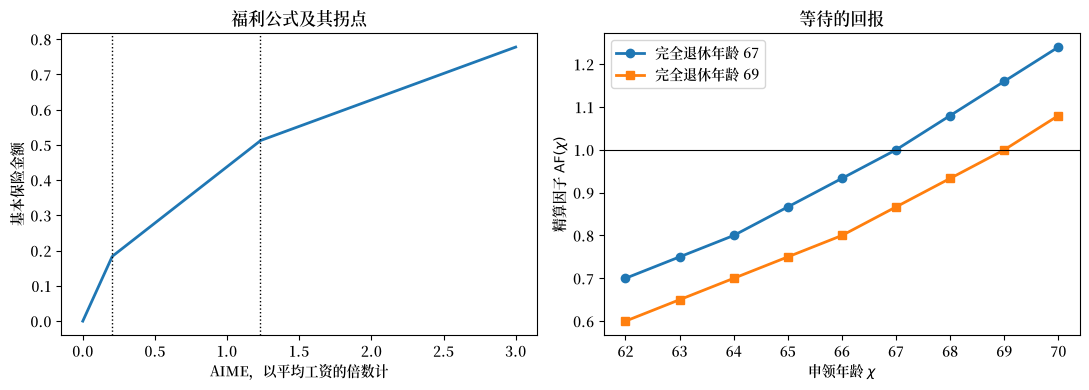

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

grid = np.linspace(0, 3, 400)
axes[0].plot(grid, pia(grid, par), lw=2)
for b in par.bend:
    axes[0].axvline(b, color='k', ls=':', lw=1)
axes[0].set_xlabel('AIME，以平均工资的倍数计')
axes[0].set_ylabel('基本保险金额')
axes[0].set_title('福利公式及其拐点')

axes[1].plot(X_GRID, claim_factors(67), 'o-', lw=2, label='完全退休年龄 67')
axes[1].plot(X_GRID, claim_factors(69), 's-', lw=2, label='完全退休年龄 69')
axes[1].axhline(1.0, color='k', lw=0.8)
axes[1].set_xlabel('申领年龄 $\\chi$')
axes[1].set_ylabel('精算因子 $\\mathrm{AF}(\\chi)$')
axes[1].set_title('等待的回报')
axes[1].legend()
plt.tight_layout()
plt.show()

收入记录低于第一个拐点的工人，每一美元可获得 $90$ 美分的替代；高于第二个拐点的工人，替代率为 $15$ 美分。

从 $62$ 岁等到 $70$ 岁，福利会提高 $77$ 个百分点，而且该时间表是法定的：它不会因死亡率改善而变动，也不会因可支付因子下降而变动。

{ref}`ssd_ex2` 提高了完全退休年龄，即橙色线所示。

### 人口统计

死亡率遵循一个冈珀茨-梅克姆死亡力函数，该函数每年改善 $0.7$ 个百分点，直至 $2085$ 年后冻结，这样经济便会在视界范围内趋于平稳均衡。

$1990$ 年前后出生队列规模的增长率不同，我们选取这两个增长率，使模型重现受托人 $2025$ 年和 $2085$ 年的老年赡养比：每位 $20$ 至 $64$ 岁人口对应的 $65$ 岁及以上人口数从 $0.32$ 上升到 $0.50$。

In [5]:
def mortality(age, year, p):
    "按年龄和日历年份计算的死亡力；改善在2085年停止。"
    yr = np.minimum(year, 2085)
    return (5e-4 + 2.5e-5*np.exp(0.095*age))*np.exp(-p.g_m*(yr - 2025))

def cohort_survival(entry_years, p):
    "ℓ[c, j]：逐队列计算的存活到20+j岁的概率。"
    ent = np.asarray(entry_years, float).reshape(-1, 1)
    j = np.arange(J).reshape(1, -1)
    s = np.exp(-mortality(AGE0 + j, ent + j, p))
    s[:, -1] = 0.0
    return np.concatenate([np.ones((len(ent), 1)),
                           np.cumprod(s[:, :-1], axis=1)], axis=1)

YS = 1990          # 新进入队列的增长率发生变化的年份

def entry_sizes(g, years):
    "每年年满20岁的队列规模。"
    y = np.asarray(years, float)
    return np.where(y <= YS, np.exp(g[0]*(y - YS)), np.exp(g[1]*(y - YS)))

def population(g, years, p):
    "N[j, t]：每个日历年份中年龄为20+j的人数。"
    years = np.atleast_1d(years)
    out = np.zeros((J, len(years)))
    for j in range(J):
        ent = years - j
        out[j] = entry_sizes(g, ent)*cohort_survival(ent, p)[:, j]
    return out

def dependency(g, t, p):
    "每位20至64岁人口对应的65岁及以上人数。"
    n = population(g, [t], p)[:, 0]
    return n[45:].sum()/n[:45].sum()

g_pop = fsolve(lambda g: [dependency(g, 2025, par) - 0.32,
                          dependency(g, 2085, par) - 0.50], [0.02, 0.0])

print(f"进入队列的增长率在{YS}年之前为{g_pop[0]:.4f}，之后为{g_pop[1]:.4f}")
for t in (2025, 2035, 2055, 2085):
    print(f"   {t}年的赡养比: {dependency(g_pop, t, par):.3f}")
print(f"   2026年出生队列在20岁时的预期寿命: "
      f"{20 + cohort_survival([2026], par)[0].sum():.1f}")

进入队列的增长率在1990年之前为0.0103，之后为-0.0020
   2025年的赡养比: 0.320
   2035年的赡养比: 0.370
   2055年的赡养比: 0.449
   2085年的赡养比: 0.500
   2026年出生队列在20岁时的预期寿命: 84.3


{numref}`fig-ssd-demography` 是贯穿后文一切内容的发动机，值得细看。

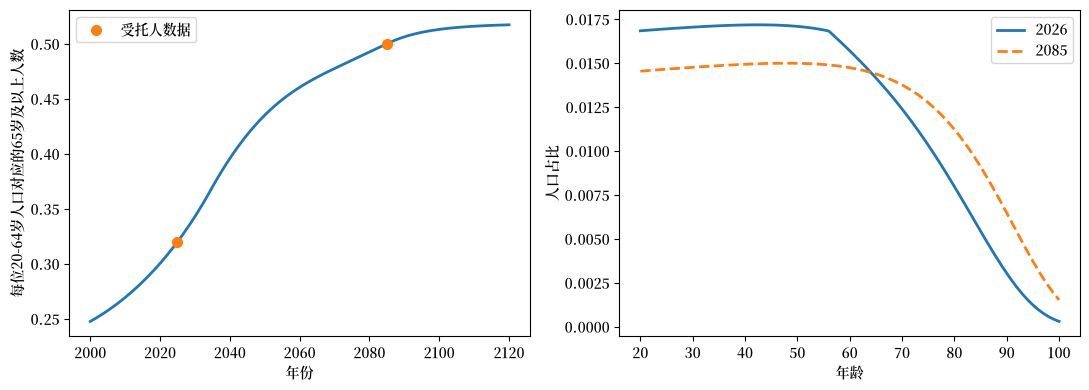

In [6]:
span = np.arange(2000, 2121)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(span, [dependency(g_pop, t, par) for t in span], lw=2)
axes[0].plot([2025, 2085], [0.32, 0.50], 'o', ms=7, color='C1',
             label='受托人数据')
axes[0].set_xlabel('年份')
axes[0].set_ylabel('每位20-64岁人口对应的65岁及以上人数')
axes[0].legend()

for t, style in ((2026, '-'), (2085, '--')):
    n_t = population(g_pop, [t], par)[:, 0]
    axes[1].plot(AGE0 + np.arange(J), n_t/n_t.sum(), style, lw=2, label=str(t))
axes[1].set_xlabel('年龄')
axes[1].set_ylabel('人口占比')
axes[1].legend()
plt.tight_layout()
plt.show()

有两股力量推高了赡养比，模型兼顾了二者。

进入劳动力市场的出生队列停止了增长，因此金字塔的底部不再扩大。

死亡率持续改善，因此金字塔的顶端不断被填满。

{ref}`ssd_ex4` 将这两者分开来看。

### 收入与类型

收入等于工资乘以一个在 $50$ 岁达到峰值的驼峰形年龄效率曲线，再乘以一个永久能力抽签值。

工人在工作偏好方面也存在差异。

两者均为对数正态分布的五点离散化，因此共有 $25$ 种类型。

In [7]:
def efficiency():
    "年龄效率曲线，在20至64岁区间归一化为均值1。"
    j = np.arange(J)
    e = np.exp(0.0583*j - 0.000972*j**2)
    return e/e[:45].mean()

ε = efficiency()

def types(p, n=5):
    "永久收入能力和工作偏好，基于张量网格。"
    x, w = np.polynomial.hermite_e.hermegauss(n)
    w = w/w.sum()
    e = np.exp(p.σ_a*x); e = e/(w*e).sum()
    h = np.exp(p.σ_η*x)
    E, H = np.meshgrid(e, h, indexing='ij')
    return E.ravel(), H.ravel(), np.outer(w, w).ravel()

收入随工作经验增加而上升，在 $50$ 岁达到峰值，此后下降。

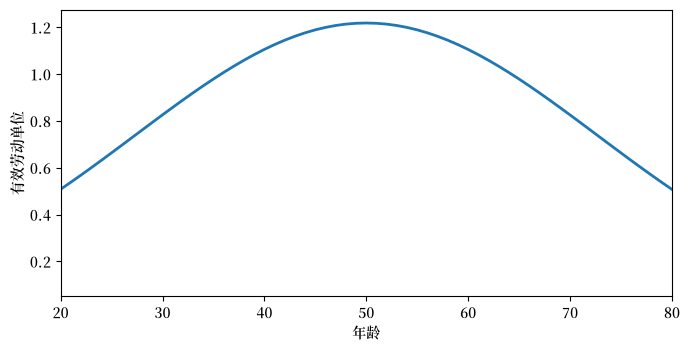

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(AGE0 + np.arange(J), ε, lw=2)
ax.set_xlabel('年龄')
ax.set_ylabel('有效劳动单位')
ax.set_xlim(20, 80)
plt.tight_layout()
plt.show()

### 工人的决策问题

工人选择何时停止工作以及何时申领福利。

这两个决策都是不可逆的，并且是独立分开的：{cite:t}`coileDiamondGruberJousten2002` 及其后续文献确立了退出劳动力市场和申领福利是两个不同的事件。

记 $R$ 为退休年龄，$\chi$ 为申领年龄，$\ell_j$ 为从 $20$ 岁存活到 $20+j$ 岁的概率。

类型为 $(e, h)$ 的工人按以下方式对计划进行排序：

```{math}
:label: ssd_utility
\sum_{j} \beta^j \ell_j
\big[\log c_j - \eta\, h\, n_j \big],
\qquad n_j = \mathbf 1\{j < R - 20\} ,
```

其中 $e$ 为永久收入能力，$h$ 为工作偏好，因此 $\eta h$ 是该工人自身对一年工作的负效用。

我们将工资归一化为一。

工作期间，工人赚取 $y_j = \varepsilon_j e$，对不超过应纳税上限 $\bar y$ 的收入缴纳劳动税和工薪税，并累积收入记录

$$
\mathrm{AIME}_{j+1} = \mathrm{AIME}_j
 + \psi\,\mathbf 1\{j < R-20\}\big(\min(y_j, \bar y) - \mathrm{AIME}_j\big),
$$

这是一个指数加权移动平均，其有效窗口为 $2/\psi - 1 \approx 35$ 年，近似于法定的最高35年规则。

一旦申领，工人领取

$$
b_j = \varsigma\,\phi_t\, \mathrm{AF}(\chi)\,\mathrm{PIA}(\mathrm{AIME}_j) ,
$$

按 $\kappa_b$ 征税，其中 $\varsigma$ 是下面校准所设定的福利规模因子。

它代表了仅针对单身工人的模型所省略的配偶和遗属福利。

在年金市场完全且效用为对数形式的条件下，消费问题有一个封闭形式的解。

年金向存活者支付总回报率 $\tilde R/s_j$，其中 $\tilde R = 1 + r(1-\tau_k)$，$s_j$ 为单期存活概率，因为去世者的余额由存活者共同分享。

将这些回报复利累积，便将存活转化为一个贴现因子：在 $20$ 岁时，$20+j$ 岁时获得的一单位收入价值为 $\ell_j \tilde R^{-j}$，终生预算约束为

```{math}
:label: ssd_budget
(1+\tau_c)\sum_j \ell_j \tilde R^{-j} c_j
= a_0 + \sum_j \ell_j \tilde R^{-j} m_j(R, \chi) \equiv \mathcal W(R,\chi) ,
```

其中 $m_j$ 是年龄 $j$ 时的净收入：工作期间为扣除两种税后的收入，申领后为扣除其自身税收后的可支付福利。

由于年金回报率与存活概率相互抵消，欧拉方程与没有死亡率的模型中的欧拉方程相同，

$$
c_j = c_0 (\beta \tilde R)^j .
$$

将其代入 {eq}`ssd_budget`，得到 $(1+\tau_c)c_0\Omega = \mathcal W$，其中 $\Omega = \sum_j \beta^j\ell_j$，再将其代入 {eq}`ssd_utility`，得到

$$
\sum_j \beta^j \ell_j \log c_j
= \Omega \log c_0 + \log(\beta\tilde R)\sum_j j\,\beta^j \ell_j .
$$

第二项不依赖于所选的计划，从 $c_0 = \mathcal W/[(1+\tau_c)\Omega]$ 中得出的 $\log[(1+\tau_c)\Omega]$ 亦然。

将两者都删去，便留下一个二维离散选择问题：

```{math}
:label: ssd_objective
\max_{R,\;\chi}\;\;
\Omega \log \mathcal W(R,\chi) \;-\; \eta\, h \sum_{j < R-20} \beta^j \ell_j .
```

第一项是该计划所带来一切（包括整个未来可支付因子路径）的现值。

第二项是额外工作年数的代价。

当消息传来时已经活着的工人，从其所处的位置解决同样的问题。

记 $j_0$ 为其 $2026$ 年时的年龄索引。

那么 {eq}`ssd_objective` 中的两个求和都从 $j_0$ 开始，而非从 $0$ 开始，$\ell_j$ 和 $\beta^j$ 也从 $j_0$ 算起；{eq}`ssd_budget` 中的 $a_0$ 是该工人在那之前已积累的财富；而它已经做出的决定则不再重新考虑。

这正是下面代码中参数 `j0`、`a0` 和 `plan0` 所承载的内容。

这里面没有什么是专属于 $2026$ 年的：{ref}`ssd_ex5` 使用相同的代码，让工人在意外消息到来的那一年重新规划。

```{note}
论文还模拟了**退休收入测试**，该测试会扣留在完全退休年龄之前仍继续工作的申领者的福利，然后通过提前有效申领年龄将其返还。

对于在完全退休年龄或之前离开工作岗位的工人，这种抵免与扣留一一对应，因此在该确定性模型中，申领时间早于退休对结果没有影响。

因此我们施加 $\chi \ge \min(R, 70)$ 的约束，并舍去该测试。

申领依然是一个独立的决策：工人可以在退休时申领，也可以等待，最晚到 $70$ 岁。

该约束确实在一个边际上有影响。

一个打算工作到完全退休年龄之后的工人可以在 $62$ 岁时申领，让福利被扣留直到该测试不再适用，然后在仍继续工作的情况下按抵免后的因子领取福利。

这种选择与晚些申领并不完全等价，而本模型将其排除在外。
```

我们列举所有可行计划，并对转型过程中活着的每个出生队列进行索引。

In [9]:
R_GRID = np.arange(58, 73)
# 工人申领时间不早于其停止工作的时间，也不晚于70岁
PLANS = np.array([(R, X) for R in R_GRID for X in X_GRID if X >= min(R, 70)])
R_P, X_P = PLANS[:, 0], PLANS[:, 1]
NP = len(PLANS)

ENTRY = np.arange(Y0-J+1, Y0+T+1)      # 每一个曾经存活过的出生队列的进入年份
NC = len(ENTRY)
ENT_IX = {y: i for i, y in enumerate(ENTRY)}
IDX = np.array([[ENT_IX[t-j] for t in YEARS] for j in range(J)])

print(f"{NP} 个可行计划，{NC} 个出生队列")

83 个可行计划，201 个出生队列


退休年龄网格从 $58$ 延伸到 $72$，且对工作偏好最极端的两种类型有约束力，这两种类型各占人口的 $1.1$ 个百分点。

将网格放宽到 $50$ 至 $80$ 会把这两种类型移到 $56$ 和 $73$，而不会改变其他任何结果：耗竭年份、两个平均年龄，以及精确到小数点后四位的可支付因子都是相同的。

我们保留窄网格，速度大约快了一倍。

所有不依赖于可支付路径的内容都只构建一次。

In [10]:
class World:
    "人口统计、类型、存活率与贴现：在迭代过程中保持固定。"

    def __init__(self, p, g):
        self.p = p
        e, h, w = types(p)
        self.NE = len(e)
        self.C = NC*self.NE
        self.entry = np.repeat(ENTRY, self.NE)
        self.e = np.tile(e, NC)
        self.η = np.tile(h, NC)
        self.w = np.tile(w, NC)
        self.j0 = np.clip(Y0 - self.entry, 0, J-1)      # 2026年时的年龄索引
        self.ell = np.repeat(cohort_survival(ENTRY, p), self.NE, axis=0)
        self.disc = self.ell/after_tax_R(p)**np.arange(J)
        self.AF = claim_factors(p.FRA)
        bet_ell = (p.β**np.arange(J))*self.ell
        self.tail = np.cumsum(bet_ell[:, ::-1], axis=1)[:, ::-1]
        self.pre = np.concatenate([np.zeros((self.C, 1)),
                                   np.cumsum(bet_ell, axis=1)], axis=1)
        self.N = population(g, YEARS, p)
        self.Npop = self.N.sum(axis=0)
        self.share = self.N/self.Npop

def phi_of(φ, year):
    "可支付因子：2026年之前为一，超出视界范围则保持不变。"
    k = np.clip(year - Y0, 0, len(φ)-1)
    return np.where(year < Y0, 1.0, np.asarray(φ)[k])

生命周期本身是对年龄的一次循环。

In [11]:
def lifecycle(W, φ, Rj, Xa, j0, disc, keep=False):
    """从年龄索引j0开始，针对计划(Rj, Xa)的贴现净收入。

    当keep=True时，还返回每个年龄的应纳税工资总额和计划福利，
    这是加总所需要的数据。
    """
    p = W.p
    nd = np.ndim(Rj)
    e_row = W.e.reshape(-1, *[1]*(nd-1))
    ent = W.entry.reshape(-1, *[1]*(nd-1))
    shape = np.broadcast(Rj, Xa, e_row).shape
    aime = np.zeros(shape)
    S = np.zeros(shape)
    AFx = np.interp(Xa, X_GRID, W.AF)*np.ones(shape)
    pay, ben = [], []
    for j in range(J):
        work = (j < Rj)*np.ones(shape)
        y = ε[j]*e_row*work
        capped = np.minimum(y, p.ycap)*work
        b = p.bscale*AFx*pia(aime, p)*((AGE0 + j >= Xa)*np.ones(shape))
        inc = ((1-p.τ_l)*y - p.τ_ss*capped
               + (1-p.κ_b)*phi_of(φ, ent + j)*b)
        S = S + np.where(j >= j0, disc[..., j]*inc, 0.0)
        if keep:
            pay.append(capped)
            ben.append(b)
        aime = aime + p.ψ*work*(capped - aime)
    return (S, np.array(pay), np.array(ben)) if keep else S

def solve_plans(W, φ, j0, plan0=None, a0=0.0, at_year=Y0):
    """使工人目标函数最大化的计划，针对每个出生队列和类型。

    工人在at_year重新规划，从其已到达的年龄索引j0开始，
    保留其携带的财富a0，以及plan0中不可撤销的决定。
    """
    p, C = W.p, W.C
    j0 = np.asarray(j0)
    S = lifecycle(W, φ, (R_P-AGE0).reshape(1, NP), X_P.reshape(1, NP),
                  j0.reshape(C, 1), W.disc.reshape(C, 1, J))
    scale = (after_tax_R(p)**j0)/W.ell[np.arange(C), j0]
    wealth = a0 + S*scale.reshape(C, 1)
    norm = (p.β**j0)*W.ell[np.arange(C), j0]
    Om = W.tail[np.arange(C), j0]/norm
    Dw = (W.pre[np.arange(C)[:, None], np.clip(R_P-AGE0, 0, J)[None, :]]
          - W.pre[np.arange(C), j0][:, None])/norm[:, None]
    V = (Om[:, None]*np.log(np.maximum(wealth, 1e-9))
         - (p.η*W.η)[:, None]*np.maximum(Dw, 0.0))
    if plan0 is not None:
        # 在at_year之前已经执行的决定不能被撤销
        R0, X0 = plan0
        age_now = np.asarray(j0) + AGE0
        alive = W.entry < at_year
        ok = np.where((alive & (R0 <= age_now))[:, None],
                      R_P[None, :] == R0[:, None],
                      R_P[None, :] >= np.where(alive, age_now, 0)[:, None])
        ok &= np.where((alive & (X0 <= age_now))[:, None],
                       X_P[None, :] == X0[:, None],
                       X_P[None, :] >= np.where(alive, np.maximum(62, age_now), 62)[:, None])
        V = np.where(ok, V, -np.inf)
    k = V.argmax(axis=1)
    return R_P[k], X_P[k], wealth[np.arange(C), k], Om, Dw[np.arange(C), k]

def flows(W, φ, R, X, j0):
    "在所选计划下每个年龄的应纳税工资总额和计划福利，形状为(J, C)。"
    _, pay, ben = lifecycle(W, φ, (R-AGE0), X, np.asarray(j0), W.disc, keep=True)
    return pay, ben

## 加总与账本

总量是各年龄段上以人口加权的平均值，算子 $\Phi$ 就是基金法则 {eq}`ssd_fund` 连同 {eq}`ssd_phi`。

In [12]:
def aggregate(W, pay, ben):
    "每个日历年份的人均应纳税工资总额和计划福利。"
    wt = W.w.reshape(NC, W.NE)[0]           # 跨出生队列平铺的类型权重
    Pj = pay.reshape(J, NC, W.NE) @ wt
    Bj = ben.reshape(J, NC, W.NE) @ wt
    Pay = (np.take_along_axis(Pj, IDX, axis=1)*W.share).sum(axis=0)
    Ben = (np.take_along_axis(Bj, IDX, axis=1)*W.share).sum(axis=0)
    return Pay, Ben

def fund_and_phi(W, Pay, Ben, F0):
    "账本及可支付因子：算子Φ的一次遍历。"
    p = W.p
    F = np.zeros(len(YEARS)+1)
    F[0] = F0
    φ = np.ones(len(YEARS))
    for t in range(len(YEARS)):
        obligations = W.Npop[t]*(1-p.κ_b)*Ben[t]
        resources = (1+p.r_F)*F[t] + W.Npop[t]*p.τ_ss*Pay[t]
        φ[t] = min(1.0, resources/obligations) if obligations > 0 else 1.0
        rev = p.τ_ss*Pay[t] + p.κ_b*φ[t]*Ben[t]
        F[t+1] = max((1+p.r_F)*F[t] + W.Npop[t]*(rev - φ[t]*Ben[t]), 0.0)
    return F, φ

## 消息传来之前的经济

$2026$ 年活着的工人在制定计划时，预期福利将永远全额支付。

我们先求解这个经济。

它为转型过程提供了两样必不可少的东西：各个出生队列到 $2026$ 年时**已经执行**的退休和申领决策，以及它们带入 $2026$ 年时所持有的资产。

它还为第三样东西提供了尺度——即信托基金的期初余额，我们将其设定为下面记录的 $2025$ 年末储备，即年度福利支出的 $1.63$ 倍。

In [13]:
def income_path(W, φ, R, X, rows=slice(None)):
    "在所选计划下每个年龄的净收入，适用于全部或部分行。"
    p = W.p
    e, entry, R, X = W.e[rows], W.entry[rows], R[rows], X[rows]
    aime = np.zeros(len(e))
    out = np.zeros((J, len(e)))
    AFx = np.interp(X, X_GRID, W.AF)
    for j in range(J):
        work = (j < R - AGE0).astype(float)
        y = ε[j]*e*work
        capped = np.minimum(y, p.ycap)*work
        b = p.bscale*AFx*pia(aime, p)*((AGE0 + j >= X).astype(float))
        out[j] = ((1-p.τ_l)*y - p.τ_ss*capped
                  + (1-p.κ_b)*phi_of(φ, entry + j)*b)
        aime = aime + p.ψ*work*(capped - aime)
    return out

def pre_transition(W):
    "当φ≡1永远成立时的计划、2026年的资产，以及总量。"
    p = W.p
    φ1 = np.ones(T+1)
    z = np.zeros(W.C, int)
    R, X, wealth, Om, _ = solve_plans(W, φ1, z)
    pay, ben = flows(W, φ1, R, X, z)
    Pay, Ben = aggregate(W, pay, ben)
    c0 = wealth/((1+p.τ_c)*Om)
    inc = income_path(W, φ1, R, X)
    a = np.zeros(W.C)
    A = np.zeros((J, W.C))
    for j in range(J-1):
        A[j] = a
        s = W.ell[:, j+1]/np.maximum(W.ell[:, j], 1e-12)
        a = (after_tax_R(p)/np.maximum(s, 1e-12))*(
            a + inc[j] - (1+p.τ_c)*c0*(p.β*after_tax_R(p))**j)
    A[J-1] = a
    return R, X, A[W.j0, np.arange(W.C)], Pay, Ben, wealth, Om

W = World(par, g_pop)
R_pre, X_pre, a26, Pay_pre, Ben_pre, wealth_pre, Om_pre = pre_transition(W)

mask = W.entry == 2026
wts = W.w[mask]/W.w[mask].sum()
print(f"2026年进入的出生队列：平均退休年龄 {(R_pre[mask]*wts).sum():.2f}，"
      f"平均申领年龄 {(X_pre[mask]*wts).sum():.2f}")
print(f"2026年的成本率: {Ben_pre[0]/Pay_pre[0]:.4f}"
      f"   （受托人对2025年的估计: 0.1362）")

2026年进入的出生队列：平均退休年龄 64.76，平均申领年龄 66.49
2026年的成本率: 0.1350   （受托人对2025年的估计: 0.1362）


有两个参数是为了得出这两个数字而选定的。

工作负效用 $\eta$ 设定了退休年龄：$2026$ 年进入的出生队列平均在 $64.8$ 岁退休，而 {cite:t}`SargentShi2026` 的目标中位退休年龄是 $64.5$ 岁。

福利规模因子 $\varsigma$ 设定了成本率，使其与受托人 $2025$ 年的数字相差不到十分之一个百分点。

申领年龄没有被设为目标，模型在这方面的偏差更大：该出生队列平均在 $66.5$ 岁申领，比该论文所匹配的 $65.0$ 岁晚了一年半。

申领时间晚于实际数据是在阅读下面的转型过程时需要牢记的一种偏差，因为申领年龄是发挥作用的两个边际之一。

另外两个未经拟合的统计量值得打印出来，因为它们都关系到模型对这两个边际的推动力有多强。

In [14]:
def replacement_rate(W, R, X):
    "首次领取的福利，相对于工作最后一年收入的比例。"
    p = W.p
    aime, last, first = (np.zeros(W.C) for _ in range(3))
    AFx = np.interp(X, X_GRID, W.AF)
    for j in range(J):
        work = (j < R - AGE0).astype(float)
        y = ε[j]*W.e*work
        capped = np.minimum(y, p.ycap)*work
        last = np.where(R - AGE0 - 1 == j, y, last)
        first = np.where(X - AGE0 == j, p.bscale*AFx*pia(aime, p), first)
        aime = aime + p.ψ*work*(capped - aime)
    return first/np.maximum(last, 1e-12)

rr = (replacement_rate(W, R_pre, X_pre)[mask]*wts).sum()
print(f"替代率，2026年进入的出生队列:      {rr:.3f}")
print(f"   按照法定公式，不含ς因子:         {rr/par.bscale:.3f}")

shares = {int(a): float(W.w[mask][X_pre[mask] == a].sum()/W.w[mask].sum())
          for a in X_GRID}
print("   所选的申领年龄:",
      {a: round(v, 3) for a, v in shares.items() if v > 0.005})

替代率，2026年进入的出生队列:      0.492
   按照法定公式，不含ς因子:         0.430
   所选的申领年龄: {66: 0.767, 68: 0.222, 70: 0.009}


第一个数字揭示了福利规模因子 $\varsigma$ 悄悄做的事情。

配偶和遗属福利是支付给*额外的人*的；而在这里，整个 $14.5$ 个百分点都落在了每个工人自己的福利上。

因此，该模型中的工人所领取的福利比法定公式所支付的多出约七分之一，相应地，退休和申领的激励也更强。

用单身工人的模型去匹配该项目的总体成本必然会使某些东西发生扭曲，而这正是扭曲所在之处。

第二个数字揭示了另一个局限性。

申领年龄集中在单一年龄上，没有人在 $62$ 岁申领。

在实际数据中，以及在该论文中，$62$ 岁和完全退休年龄都存在明显的集中峰值；而产生 $62$ 岁峰值的那些因素——流动性约束、健康状况、结束职业生涯的糟糕收入抽签——恰恰是这个版本所省略的。

## 求解均衡可支付路径

现在把消息告诉工人。

从 $\phi_t \equiv 1$ 开始，我们应用 $\Phi$，向结果迈出一步阻尼步长，然后重复这个过程。

步长从二分之一开始，并像 {cite:t}`SargentShi2026` 的求解器那样逐渐退火到一个下限。

In [15]:
def transition(W, F0, plan0, a0, iters=40, tol=1e-4,
               ν0=0.5, anneal=0.92, floor=0.08, verbose=True):
    "对可支付路径的阻尼迭代。"
    φ = np.ones(T+1)
    for k in range(iters):
        R, X, _, _, _ = solve_plans(W, φ, W.j0, plan0=plan0,
                                    a0=a0.reshape(W.C, 1))
        pay, ben = flows(W, φ, R, X, W.j0)
        Pay, Ben = aggregate(W, pay, ben)
        F, φ_new = fund_and_phi(W, Pay, Ben, F0)
        gap = np.abs(φ_new - φ).max()
        ν = max(ν0*anneal**k, floor)
        φ = (1-ν)*φ + ν*φ_new
        if verbose and k % 5 == 0:
            print(f"   迭代 {k:>3}   步长 {ν:.3f}   差距 {gap:.2e}"
                  f"   2033年的φ {φ[2033-Y0]:.4f}")
        if gap < tol:
            break
    return dict(φ=φ, F=F, R=R, X=X, Pay=Pay, Ben=Ben)

F0 = par.F_ratio*W.Npop[0]*Ben_pre[0]
base = transition(W, F0, (R_pre, X_pre), a26)

   迭代   0   步长 0.500   差距 5.23e-01   2033年的φ 0.9725
   迭代   5   步长 0.330   差距 4.31e-02   2033年的φ 0.7717
   迭代  10   步长 0.217   差距 1.51e-02   2033年的φ 0.7578
   迭代  15   步长 0.143   差距 1.72e-02   2033年的φ 0.7560
   迭代  20   步长 0.094   差距 1.18e-02   2033年的φ 0.7555
   迭代  25   步长 0.080   差距 1.44e-02   2033年的φ 0.7553
   迭代  30   步长 0.080   差距 1.41e-02   2033年的φ 0.7551
   迭代  35   步长 0.080   差距 1.48e-02   2033年的φ 0.7550


   迭代   5   步长 0.330   差距 4.31e-02   2033年的φ 0.7717


   迭代  10   步长 0.217   差距 1.51e-02   2033年的φ 0.7578


   迭代  15   步长 0.143   差距 1.72e-02   2033年的φ 0.7560


   迭代  20   步长 0.094   差距 1.18e-02   2033年的φ 0.7555


   迭代  25   步长 0.080   差距 1.44e-02   2033年的φ 0.7553


   迭代  30   步长 0.080   差距 1.41e-02   2033年的φ 0.7551


   迭代  35   步长 0.080   差距 1.48e-02   2033年的φ 0.7550


收敛后的路径给出了两个日期以及削减的大小。

In [16]:
φ, F = base['φ'], base['F']
depletion = YEARS[np.argmax(F[:-1] <= 1e-12)]
shortfall = YEARS[np.argmax(φ < 1)]
print(f"首个短缺年: {shortfall}")
print(f"耗竭年份:       {depletion}")
print(f"{shortfall}年的φ: {φ[shortfall-Y0]:.3f}，{depletion}年的φ: {φ[depletion-Y0]:.3f}，"
      f"  长期值: {φ[-1]:.3f}")

首个短缺年: 2032
耗竭年份:       2033
2032年的φ: 0.952，2033年的φ: 0.755，  长期值: 0.482


这些日期正是受托人所预测的日期，首次全年削减的幅度也与他们的预测接近：他们估计在基金为空的第一年中，持续的收入将能覆盖计划福利的约 $78$ 个百分点。

这两个日期都没有被设为目标。

该校准固定的是单独一年（$2025$ 年）的成本率，期初余额则取自记录值；该余额耗尽的那一年取决于中间若干年的现金流，而这些现金流又取决于日益下降的可支付因子本身所引发的申领和退休决策。

findfont: Failed to find font weight normal, now using 600.


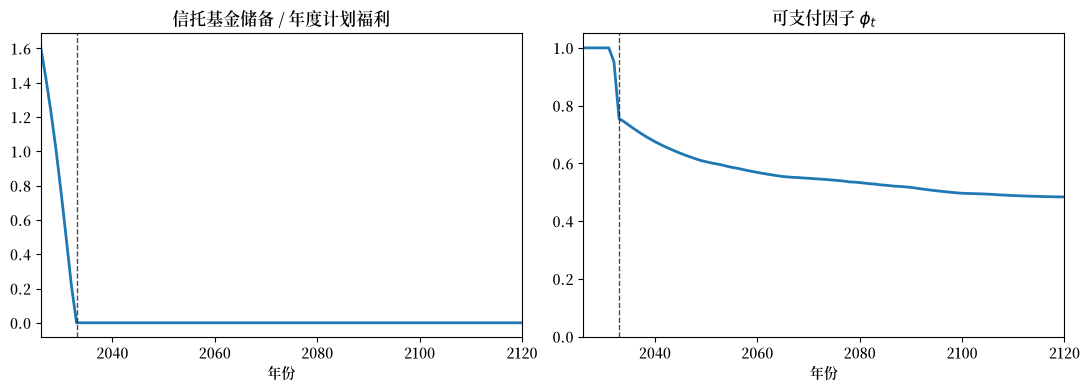

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(YEARS, F[:-1]/(W.Npop*base['Ben']), lw=2)
axes[0].set_title('信托基金储备 / 年度计划福利')
axes[1].plot(YEARS, φ, lw=2)
axes[1].set_title('可支付因子 $\\phi_t$')
axes[1].set_ylim(0, 1.05)
for ax in axes:
    ax.axvline(depletion, color='k', ls='--', lw=1, alpha=0.7)
    ax.set_xlabel('年份')
    ax.set_xlim(Y0, 2120)
plt.tight_layout()
plt.show()

可支付因子并不会在基金耗空的那一天所达到的水平上稳定下来。

在本世纪剩余时间内，它会进一步下降，因为赡养比持续上升。

根据 {eq}`ssd_longrun`，长期削减完全由该项目的成本率所决定，我们可以在计算出的路径上验证这一恒等式。

In [18]:
cost = base['Ben']/base['Pay']
print(f"终端成本率: {cost[-1]:.4f}")
print(f"τ_ss/[(1-κ_b)·成本率] = {par.τ_ss/((1-par.κ_b)*cost[-1]):.4f}"
      f"   对应于 φ_∞ = {φ[-1]:.4f}")

终端成本率: 0.2291
τ_ss/[(1-κ_b)·成本率] = 0.4814   对应于 φ_∞ = 0.4816


## 转型过程中的申领和退休

两个决策都对 $\phi_t$ 的路径作出反应，并且都在削减发生时逆转方向。

In [19]:
def flow_ages(W, R, X):
    "以人口加权的新退休者和新申领者的平均年龄。"
    wt = W.w.reshape(NC, W.NE)[0]
    age = (AGE0 + np.arange(J)).reshape(J, 1, 1)
    hitR = (R.reshape(1, NC, W.NE) == age)*wt
    hitX = (X.reshape(1, NC, W.NE) == age)*wt
    nR = np.take_along_axis(hitR.sum(axis=2), IDX, axis=1)*W.share
    nX = np.take_along_axis(hitX.sum(axis=2), IDX, axis=1)*W.share
    ages = (AGE0 + np.arange(J)).reshape(J, 1)
    return ((nR*ages).sum(axis=0)/np.maximum(nR.sum(axis=0), 1e-12),
            (nX*ages).sum(axis=0)/np.maximum(nX.sum(axis=0), 1e-12))

mean_R, mean_X = flow_ages(W, base['R'], base['X'])

这两个平均年龄同步变动，并且都在削减发生时转向。

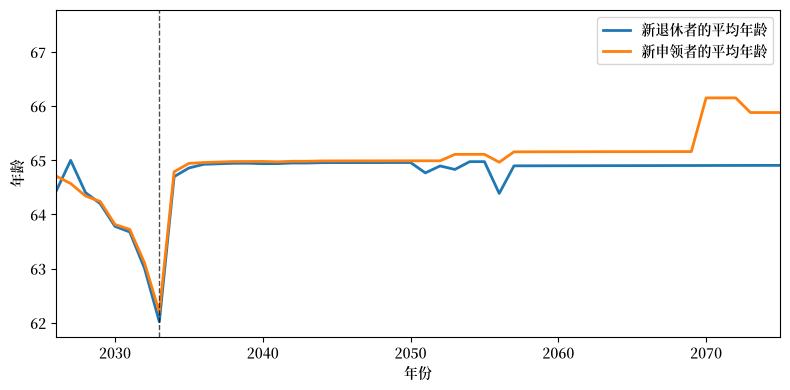

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(YEARS, mean_R, lw=2, label='新退休者的平均年龄')
ax.plot(YEARS, mean_X, lw=2, label='新申领者的平均年龄')
ax.axvline(depletion, color='k', ls='--', lw=1, alpha=0.7)
ax.set_xlabel('年份')
ax.set_ylabel('年龄')
ax.set_xlim(Y0, 2075)
ax.legend()
plt.tight_layout()
plt.show()

随着基金逐渐枯竭，出现了一种**抢先效应**。

从 $2026$ 年开始，两个年龄逐年下降，新申领者的平均年龄在基金为空的第一年降至 $62.2$ 岁，而起始时为 $64.7$ 岁。

处于申领窗口内的工人尽早申领，因为申领固定了精算因子，而在这些年份中的支付仍然全额或接近全额支付。

而等待的工人将在之后年份的削减因子下领取福利。

此后的一年，这种模式发生逆转：已没有什么可以抢先争取的了，两个年龄都反弹回 $64.5$ 岁以上，随后缓慢上升，长期达到 $65.3$ 岁和 $66.6$ 岁。

养老金变小了，于是职业生涯延长；而死亡率持续改善，精算时间表仍保持其法定数值，因此较晚申领能在更多年份里获得更高的福利。

大约在 $2075$ 年之后，平均申领年龄在两个相邻整数之间抖动，这就是为什么 {numref}`fig-ssd-flow-ages` 在那里停止；下面关于计算的说明解释了原因。

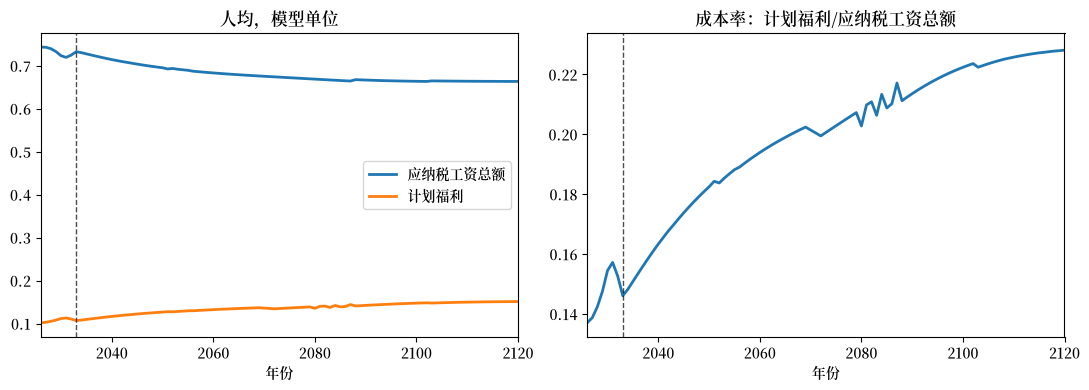

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(YEARS, base['Pay'], lw=2, label='应纳税工资总额')
axes[0].plot(YEARS, base['Ben'], lw=2, label='计划福利')
axes[0].legend()
axes[0].set_title('人均，模型单位')
axes[1].plot(YEARS, cost, lw=2)
axes[1].set_title('成本率：计划福利/应纳税工资总额')
for ax in axes:
    ax.axvline(depletion, color='k', ls='--', lw=1, alpha=0.7)
    ax.set_xlabel('年份')
    ax.set_xlim(Y0, 2120)
plt.tight_layout()
plt.show()

福利公式按两条时间线运行，{numref}`fig-ssd-cost-rate` 的右图展示了两者。

更长的职业生涯**立即**为应纳税工资总额增加了纳税人。

较晚申领会立即降低计划账单，因为它减少了申领者的数量，而只有在**数十年后**，当延迟申领者开始领取带有更高精算因子的福利时，才会提高账单。

因此，成本率在削减发生前的几年里有所上升，因为抢先效应增加了申领者；而在之后的一两年中则回落，因为申领再次被推迟，随后才恢复其上升趋势。

一旦基金耗空，{eq}`ssd_phiflow` 使可支付因子恰好与成本率的倒数成比例，因此那次下降对应的是一次未发生的福利削减。

按 $2031$ 年的成本率计算，该公式本应支付 $\phi = 0.702$；而工人自身的反应在 $2033$ 年实际带来的是 $0.755$。

{cite:t}`SargentShi2026` 发现，这种不对称性足够强，使得可支付因子在削减之后会先恢复几年，然后再恢复其下降趋势。

而在这里，这种恢复体现在成本率中，却没有体现在 $\phi_t$ 本身：这次下降幅度不够大，无法超过仍在上升的赡养比。

### 谁在抢先行动

流量平均值掩盖了谁在抢先行动，因此逐个出生队列审视这些决策是值得的。

{numref}`fig-ssd-who-rushes` 针对工人在 $2026$ 年的年龄，绘制了消息传来之前所制定的计划和消息之后所选择的计划。

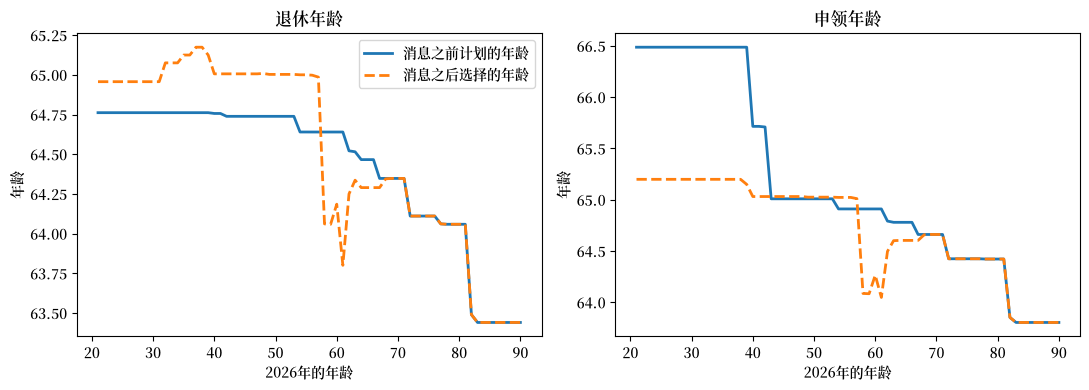

In [22]:
ages26 = np.arange(21, 91)

def by_age26(vals):
    "2026年每个出生队列中各类型决策的加权平均。"
    out = np.zeros(len(ages26))
    for i, a in enumerate(ages26):
        m = W.entry == Y0 - (a - AGE0)
        out[i] = (vals[m]*W.w[m]).sum()/W.w[m].sum()
    return out

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, before, after, title in (
        (axes[0], R_pre, base['R'], '退休年龄'),
        (axes[1], X_pre, base['X'], '申领年龄')):
    ax.plot(ages26, by_age26(before), lw=2, label='消息之前计划的年龄')
    ax.plot(ages26, by_age26(after), lw=2, ls='--', label='消息之后选择的年龄')
    ax.set_xlabel('2026年的年龄')
    ax.set_ylabel('年龄')
    ax.set_title(title)
axes[0].legend()
plt.tight_layout()
plt.show()

{numref}`fig-ssd-who-rushes` 中出现了三个群体。

到 $2026$ 年已经退休并已申领的工人，坚守着他们原来的计划，因为两个决策都是不可逆的：两条线在每个图的右侧重合。

处于或接近申领窗口的工人最先行动，也最早行动：他们比原计划更早申领，其中一些人也更早离开工作岗位，以便在福利仍全额支付时领取。

四十多岁及更年轻的工人在一个边际上走相反的方向，而在另一个边际上则随大流。

他们工作更长时间，因为他们的养老金更少。

但他们**提前**了一年多申领，比原计划更早：由于可支付因子逐年下降，推迟领取的福利意味着在更低的因子下领取，这与等待所能带来的精算回报相抵触。

### 一位工人的生命周期

消息对单个工人的影响比它对总量的影响更容易看清。

{numref}`fig-ssd-life-cycle` 追踪了 $2026$ 年进入的出生队列中的中位类型，在消息传来前后的整个生命周期。

In [23]:
R_b, X_b, wealth_b, Om_b, _ = solve_plans(W, φ, W.j0, plan0=(R_pre, X_pre),
                                          a0=a26.reshape(W.C, 1))

def life_profile(W_, φ_, R, X, wealth, Om, row):
    "单个工人按年龄的净收入、消费和资产。"
    p = W_.p
    m = income_path(W_, φ_, R, X, rows=[row])[:, 0]
    c = wealth[row]/((1+p.τ_c)*Om[row])*(p.β*after_tax_R(p))**np.arange(J)
    a = np.zeros(J)
    for j in range(J-1):
        s = W_.ell[row, j+1]/W_.ell[row, j]
        a[j+1] = (after_tax_R(p)/s)*(a[j] + m[j] - (1+p.τ_c)*c[j])
    return m, c, a

row = np.where(W.entry == 2026)[0][12]          # 中位类型
before = life_profile(W, np.ones(T+1), R_pre, X_pre, wealth_pre, Om_pre, row)
after = life_profile(W, φ, R_b, X_b, wealth_b, Om_b, row)

三个图：工人所领取的、所花费的，以及所持有的。

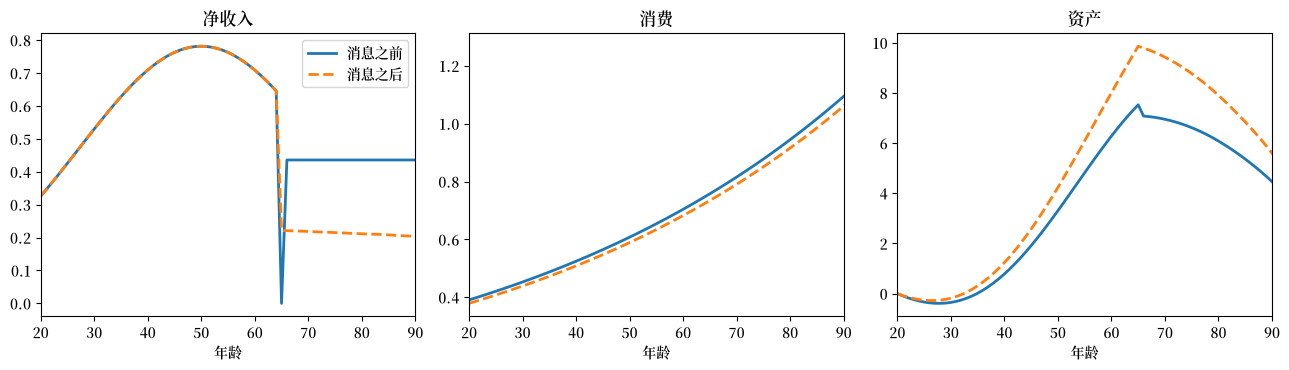

退休年龄 65 -> 65，申领年龄 66 -> 65
资产峰值    7.53 -> 9.86


In [24]:
age = AGE0 + np.arange(J)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for k, ttl in enumerate(('净收入', '消费', '资产')):
    axes[k].plot(age, before[k], lw=2, label='消息之前')
    axes[k].plot(age, after[k], lw=2, ls='--', label='消息之后')
    axes[k].set_title(ttl)
    axes[k].set_xlabel('年龄')
    axes[k].set_xlim(20, 90)
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"退休年龄 {R_pre[row]} -> {R_b[row]}，申领年龄 {X_pre[row]} -> {X_b[row]}")
print(f"资产峰值    {before[2].max():.2f} -> {after[2].max():.2f}")

这位工人的退休年龄没有改变——该选择是一个整数，而一个移动一年的总量，是因为不同工人在不同日期做出转换——但该工人提前了一年申领，在每个年龄都消费得更少，并在退休时携带约多三分之一的资产。

{numref}`fig-ssd-life-cycle` 的收入图还展示了消息传来之前的计划所愿意支付的另一件事。

$65$ 岁退休、$66$ 岁申领，会留下一年完全没有收入的空档，靠储蓄来过渡，以换取永久更高的精算因子。

这个过渡空档正是消息所剥夺的第一件事。

消费的上扬斜率源自 $\beta\tilde R > 1$：在税后回报率为 $4.2$ 个百分点的情况下，该工人足够有耐心，想要一个上升的消费路径。

第三幅图是储蓄反应，在一般均衡中，它将深化资本存量并提高工资，进而提高应纳税工资总额：这正是本讲座所关闭、而论文所保留的渠道。

## 与完整模型的比较

下表将这个精简模型的结果，与 {cite:t}`SargentShi2026` 的一般均衡数字并列展示。

In [25]:
rows = [("首个短缺年",            f"{shortfall}",            "2032"),
        ("基金从何时起耗空",                 f"{depletion}",            "2033"),
        ("首个全额削减年的φ值",    f"{φ[depletion-Y0]:.3f}",  "0.773"),
        ("长期φ值",               f"{φ[-1]:.3f}",            "0.546"),
        ("2026年平均申领年龄",            f"{mean_X[0]:.1f}",        "65.0"),
        ("长期平均申领年龄",        f"{mean_X[-1]:.1f}",       "69.2"),
        ("2026年平均退休年龄",       f"{mean_R[0]:.1f}",        "62.7"),
        ("长期平均退休年龄",   f"{mean_R[-1]:.1f}",       "66.2"),
        ("2026年成本率",                 f"{cost[0]:.3f}",          "0.136")]

print(f"{'':34}{'本讲座':>14}{'该论文':>12}")
for name, mine, theirs in rows:
    print(f"{name:34}{mine:>14}{theirs:>12}")

                                             本讲座         该论文
首个短缺年                                       2032        2032
基金从何时起耗空                                    2033        2033
首个全额削减年的φ值                                 0.755       0.773
长期φ值                                       0.482       0.546
2026年平均申领年龄                                 64.7        65.0
长期平均申领年龄                                    66.6        69.2
2026年平均退休年龄                                 64.4        62.7
长期平均退休年龄                                    65.3        66.2
2026年成本率                                   0.137       0.136


两个日期是一致的，每一个反应的方向也是一致的。

有两点不一致，两点都值得清楚说明。

长期削减在这里更深，为 $0.482$，而论文中为 $0.546$。

本讲座中价格固定不变，因此那种提高工资、进而提高应纳税工资总额的资本深化效应就缺失了；而本讲座中的人口统计是一个平滑的风格化处理，而非受托人的预测数据。

此处的行为反应也**比**论文中的**更小**，而不仅仅是中心位置不同。

在整个转型过程中，平均退休年龄上升了 $0.9$ 年，而论文中为 $3.5$ 年；平均申领年龄上升了 $1.9$ 年，而论文中为 $4.2$ 年。

精简模型的三个特征抑制了这些反应：工人不面临特异性收入风险，因此没有人因一次糟糕的抽签而被推过某个阈值；每个工人的选择是一个整数，因此只有当收益跨越一整年时，某种类型才会作出反应；而且价格不变，工资从不对更长的职业生涯给予回报。

关于退休*水平*还需要再加一点提醒：论文中的 $62.7$ 是一个被特异性冲击所产生的早期退休左尾拉低的均值，而其中位数——这正是本讲座校准所匹配的目标——是 $64.5$。

```{admonition} 一般均衡模型增加了什么
:class: tip

**减税与福利削减同时到来。** 耗竭将社会保障赤字从合并联邦预算中移除，因此劳动税在长期从 $0.220$ 降至 $0.190$。现行法律在同一年既削减了退休人员的福利，又减少了工人的税负。

**资本不断深化。** 每一个在工作的出生队列都在为更小的养老金而储蓄，资本—产出比从 $3.00$ 上升到 $3.19$，利率从 $6.0$ 下降到 $5.3$ 个百分点，工资则上升。

**为纾困融资代价高昂，而且其排序并非资本的排序。** 在终端稳态中，让新生代全额支付每一份计划福利，在消费税融资下，成本是终生消费的 $4.8$ 个百分点，在资本税融资下为 $8.7$ 个百分点，在工资税融资下为 $11.6$ 个百分点。资本税对资本的收缩作用最大，但仍比工资税便宜，因为工资税扭曲了退休这一边际——而该经济正是依靠这一边际来缓解对该项目的压力——同时也侵蚀了它自身的税基。

**一项项目改革改变了算术。** 将完全退休年龄从 $67$ 提高到 $69$ 岁，能将耗竭推迟十年，并将长期可支付因子从 $0.546$ 提高到 $0.621$。提高应纳税上限并削减最高替代率，则改变了负担的分配，而耗竭年份不变。

**宣布的时间点在在世人群中重新分配利益。** 对于 $2026$ 年时 $60$ 岁的工人，纾困价值约为剩余终生消费的 $+4.5$ 个百分点；而对于 $25$ 岁的工人，则约为 $-2$ 个百分点。
```

```{admonition} 计算完整模型
:class: note

该论文的求解器具有与上述相同的结构，只是规模不同。

工人的决策问题是一个具有资产、特异性生产率冲击、永久能力、收入记录和申领状态作为状态变量的动态规划，通过对 $81$ 个年龄和 $150$ 个日历年份进行逆向归纳来求解；截面数据是每个年龄单元 $80{,}000$ 名工人的面板数据，使用共同的随机数向前模拟，这样每种情景都面对相同的工人和相同的冲击。

平稳均衡通过安德森加速法求得，转型过程则是对价格、遗赠转移、可支付路径和暂时性税率的阻尼迭代，与本讲座中的做法相同。

代码使用 JAX 编写，在 A100 GPU 上运行：对于全部实验从冷启动开始大约需要 $22$ 小时，或者大约一小时即可重放已存储的收敛路径。

该论文还报告了阻尼无法消除的一个残差。

由于周期是以年为单位，该迭代可能在两个相邻的首个短缺年之间循环，每一个都蕴含着另一个。

我们自己的迭代也以类似的方式陷入停滞，原因也相关：退休和申领年龄是整数，因此有一大批工人会不连续地切换，使得 $\Phi$ 不是连续的。

在上面的输出中，差距在大约 $10^{-2}$ 处停止下降，而旁边打印出的可支付因子则稳定到小数点后第四位。
```

## 练习

```{exercise}
:label: ssd_ex1

上面的框注声称 $\Phi$ 是一个递减映射，这也是本讲座中每一次迭代都采用阻尼的原因。

分两步验证这一点。

1. 取收敛后的路径，将 $2033$ 年起每一年的数值提高五个百分点，并应用一次 $\Phi$。其像是上升还是下降？
1. 从 $\phi \equiv 1$ 开始，运行**未经阻尼的**迭代，即 $\phi_{k+1} = \Phi(\phi_k)$，共进行二十步，并将 $2040$ 年和 $2080$ 年的可支付因子相对于迭代次数绘制出来。将两者都与阻尼迭代进行比较。未经阻尼的迭代是否收敛？
```

```{solution-start} ssd_ex1
:class: dropdown
```

对于第1部分，对该算子应用一次相当于对 `solve_plans`、`flows`、`aggregate` 和 `fund_and_phi` 各调用一次。

In [26]:
def Phi(W, φ, F0, plan0, a0):
    "算子Φ的一次应用。"
    R, X, _, _, _ = solve_plans(W, φ, W.j0, plan0=plan0, a0=a0.reshape(W.C, 1))
    pay, ben = flows(W, φ, R, X, W.j0)
    Pay, Ben = aggregate(W, pay, ben)
    return fund_and_phi(W, Pay, Ben, F0)[1]

φ_up = φ.copy()
φ_up[depletion-Y0:] += 0.05

im_0 = Phi(W, φ, F0, (R_pre, X_pre), a26)
im_up = Phi(W, φ_up, F0, (R_pre, X_pre), a26)

k = 2050 - Y0
print(f"2050年的φ:            {φ[k]:.4f}  ->  提高后为 {φ_up[k]:.4f}")
print(f"2050年的Φ(φ):         {im_0[k]:.4f}  ->  {im_up[k]:.4f}")
print(f"2033-2100年间Φ(φ)的平均变化: "
      f"{(im_up - im_0)[depletion-Y0:2100-Y0].mean():+.4f}")

2050年的φ:            0.6056  ->  提高后为 0.6556
2050年的Φ(φ):         0.6044  ->  0.6004
2033-2100年间Φ(φ)的平均变化: -0.0027


其像朝着相反的方向移动：更慷慨的承诺带来了更早的申领和更早的退休，这降低了应纳税工资总额并提高了计划账单，因此该项目只能支付更小的比例。

对于第2部分，对递减映射的迭代会围绕其不动点来回交替，而这种交替是否会消失取决于反应的强弱。

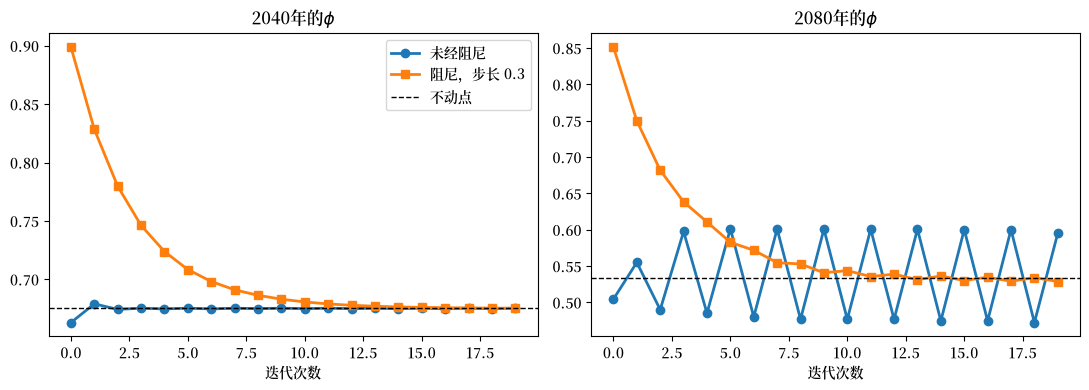

未经阻尼，20步后的最大残差: 0.168
阻尼，   20步后的最大残差: 0.025


In [27]:
def trace(ν, years=(2040, 2080), n=20):
    "在步长为ν的迭代中，选定日期的可支付因子。"
    φ_k = np.ones(T+1)
    out, gaps = [], []
    for _ in range(n):
        φ_new = Phi(W, φ_k, F0, (R_pre, X_pre), a26)
        gaps.append(np.abs(φ_new - φ_k).max())
        φ_k = (1-ν)*φ_k + ν*φ_new
        out.append([φ_k[y-Y0] for y in years])
    return np.array(out), np.array(gaps)

un, gap_un = trace(1.0)
dp, gap_dp = trace(0.3)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k, y in enumerate((2040, 2080)):
    axes[k].plot(un[:, k], 'o-', lw=2, label='未经阻尼')
    axes[k].plot(dp[:, k], 's-', lw=2, label='阻尼，步长 0.3')
    axes[k].axhline(φ[y-Y0], color='k', ls='--', lw=1, label='不动点')
    axes[k].set_title(f'{y}年的$\\phi$')
    axes[k].set_xlabel('迭代次数')
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"未经阻尼，20步后的最大残差: {gap_un[-1]:.3f}")
print(f"阻尼，   20步后的最大残差: {gap_dp[-1]:.3f}")

在 $2040$ 年，未经阻尼的迭代会交替并趋于稳定：在那个日期，申领和退休对可支付因子的反应足够微弱，使得 $\Phi$ 在那里是一个压缩映射。

在 $2080$ 年则不然。

未经阻尼的序列锁定在大约 $0.48$ 到 $0.60$ 之间的一个二周期中，并停留在那里：每一个可支付因子所引发的决策都证明了另一个可支付因子的合理性，迭代便永远在两者之间摇摆不定。

阻尼序列稳定在两者之间。

这就是为什么本讲座中每个求解器都采用一个分数步长，也是为什么 {cite:t}`SargentShi2026` 将他们的步长退火到一个下限的原因。

```{solution-end}
```

```{exercise}
:label: ssd_ex2

在 {cite:t}`SargentShi2026` 研究的各项改革中，只有一项改革会移动耗竭日期：将完全退休年龄从 $67$ 提高到 $69$。

该改革在 $2026$ 年宣布，并立即适用于所有人，包括当前的受益人。

它完全通过精算因子发挥作用：在完全退休年龄为 $69$ 的情况下，每个申领年龄对应的精算因子都约低 $13$ 个百分点，这就是 {numref}`fig-ssd-benefit-rules` 右图中两条线之间的差距，而申领窗口仍在 $70$ 岁时关闭，因此工人只能通过更晚申领来收回部分被削减的部分。

计算改革后的转型路径，并报告耗竭年份和长期可支付因子。

耗竭被推迟了多少年？该改革抵消了长期福利削减的多大比例？
```

```{solution-start} ssd_ex2
:class: dropdown
```

只有精算时间表发生变化，因此我们用 `FRA=69` 构建一个新的 `World`，并从相同的初始条件运行相同的转型。

In [28]:
W69 = World(par._replace(FRA=69), g_pop)
base69 = transition(W69, F0, (R_pre, X_pre), a26, verbose=False)

φ69, F69 = base69['φ'], base69['F']
dep69 = YEARS[np.argmax(F69[:-1] <= 1e-12)]

print(f"{'':28}{'FRA 67':>10}{'FRA 69':>10}")
print(f"{'耗竭年份':28}{depletion:>10}{dep69:>10}")
print(f"{'长期φ值':28}{φ[-1]:>10.3f}{φ69[-1]:>10.3f}")
print(f"{'长期成本率':28}"
      f"{cost[-1]:>10.3f}{(base69['Ben']/base69['Pay'])[-1]:>10.3f}")

                                FRA 67    FRA 69
耗竭年份                              2033      2040
长期φ值                             0.482     0.568
长期成本率                            0.229     0.195


该改革提升了整条可支付路径，两者之间的差距永远不会消失。

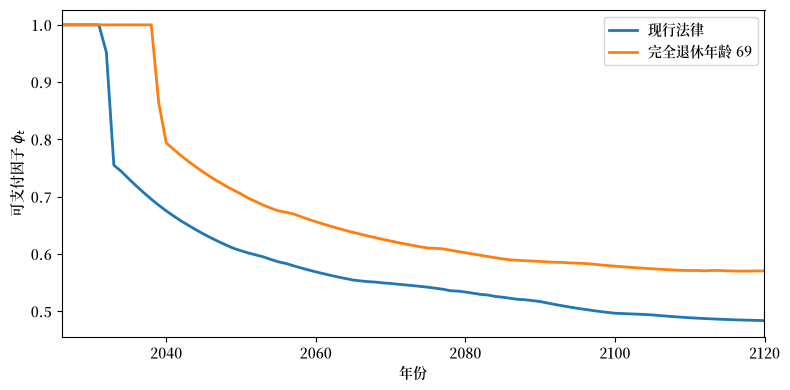

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(YEARS, φ, lw=2, label='现行法律')
ax.plot(YEARS, φ69, lw=2, label='完全退休年龄 69')
ax.set_xlabel('年份')
ax.set_ylabel('可支付因子 $\\phi_t$')
ax.set_xlim(Y0, 2120)
ax.legend()
plt.tight_layout()
plt.show()

耗竭被推迟了七年，从 $2033$ 推迟到 $2040$ 年，而论文中报告的是十年。

长期削减幅度从计划福利的 $51.8$ 个百分点降至 $43.2$ 个百分点，因此该改革抵消了约六分之一的削减。

它之所以能起作用，是因为它立即削减了计划账单，对当前受益人和未来受益人都是如此，因此基金可以持续更久，而现金流条件 {eq}`ssd_phiflow` 此后将在一个永远更高的可支付因子处出清。

它并没有恢复计划福利，而是降低了计划福利。

工人*实际领取*的福利是这两个因子的乘积，该改革通过削减其中一个因子来提高另一个因子。

```{solution-end}
```

```{exercise}
:label: ssd_ex3

假设国会不让削减发生，而是保证每一份计划福利，即 $\phi_t = 1$ 永远成立，并通过从 $2026$ 年起将工薪税 $\tau^{ss}$ 提高到一个新的常数来为此融资。

1. 找出能使该项目长期现金流达到平衡的税率，并考虑到工人会对此作出反应。
1. 计算该保证对 $2026$ 年至 $2096$ 年间进入的出生队列的消费等价变化。根据封闭形式 {eq}`ssd_objective`，一个出生队列的终生价值为 $V = \Omega\log\mathcal W - \eta h D$，使两种经济等价的补偿为 $\lambda = \exp\big(\sum_i w_i \Delta V_i/\Omega\big) - 1$。
1. 对**已经活着的**工人也做同样的计算，作为其年龄的函数。谁从该保证中受益，谁为此买单？
```

```{solution-start} ssd_ex3
:class: dropdown
```

对于第1部分，在 $\phi_t \equiv 1$ 的情况下，$\phi$ 中不再有不动点需要求解：我们只需要求出使该项目长期现金流平衡的工薪税率，而工人对该税率的反应已经包含在 $\mathit{Pay}$ 和 $B^{sch}$ 之中。

In [30]:
def program_gap(τ, plan0, a0):
    "当每份福利都全额支付时，该项目的长期现金流。"
    W_τ = World(par._replace(τ_ss=τ), g_pop)
    R, X, _, _, _ = solve_plans(W_τ, np.ones(T+1), W_τ.j0,
                                plan0=plan0, a0=a0.reshape(W_τ.C, 1))
    pay, ben = flows(W_τ, np.ones(T+1), R, X, W_τ.j0)
    Pay, Ben = aggregate(W_τ, pay, ben)
    return τ*Pay[-1] - (1-par.κ_b)*Ben[-1]

τ_star = brentq(lambda τ: program_gap(τ, (R_pre, X_pre), a26), 0.10, 0.40, xtol=1e-4)
print(f"为保证融资所需的工薪税率: {τ_star:.4f}"
      f"   （现行法律为: {par.τ_ss}）")

为保证融资所需的工薪税率: 0.2229   （现行法律为: 0.106）


对于第2部分，我们从两种经济中 `solve_plans` 的结果中读取终生价值。

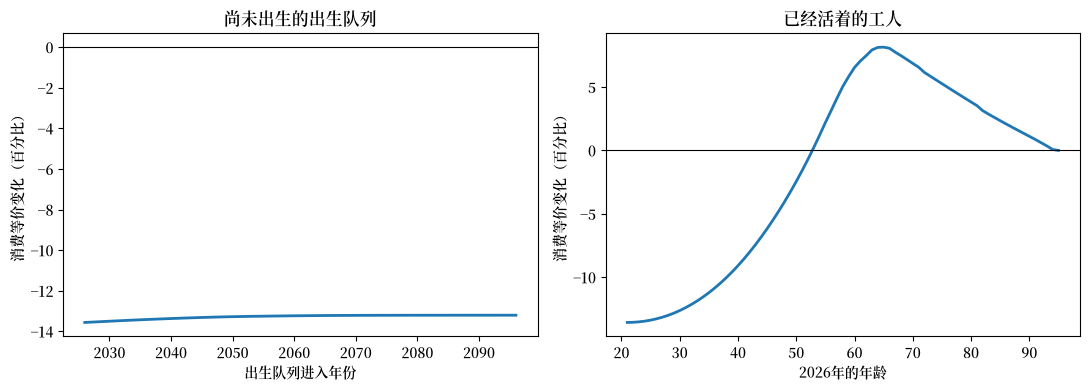

2026年进入: -13.56 个百分点
2096年进入: -13.20 个百分点
   2026年25岁: -13.39 个百分点
   2026年45岁: -6.18 个百分点
   2026年60岁: +6.54 个百分点
   2026年65岁: +8.14 个百分点
   2026年80岁: +3.82 个百分点


In [31]:
def cohort_values(W_, φ_, plan0, a0):
    "每一行的终生价值，以及加总所需的权重和Ω。"
    R, X, wealth, Om, Dw = solve_plans(W_, φ_, W_.j0, plan0=plan0,
                                       a0=a0.reshape(W_.C, 1))
    V = Om*np.log(wealth) - (W_.p.η*W_.η)*Dw
    return V, Om

V_dep, Om_dep = cohort_values(W, φ, (R_pre, X_pre), a26)
W_bail = World(par._replace(τ_ss=τ_star), g_pop)
V_bail, _ = cohort_values(W_bail, np.ones(T+1), (R_pre, X_pre), a26)

def cev(entry_year):
    "该保证的消费等价变化，逐个出生队列计算。"
    m = W.entry == entry_year
    wts = W.w[m]/W.w[m].sum()
    return np.exp(((V_bail[m] - V_dep[m])*wts).sum()/Om_dep[m][0]) - 1

entries = np.arange(2026, 2097)
λ_new = np.array([cev(y) for y in entries])
ages = np.arange(21, 96)
λ_old = np.array([cev(Y0 - (a - AGE0)) for a in ages])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(entries, 100*λ_new, lw=2)
axes[0].set_xlabel('出生队列进入年份')
axes[0].set_title('尚未出生的出生队列')
axes[1].plot(ages, 100*λ_old, lw=2)
axes[1].set_xlabel('2026年的年龄')
axes[1].set_title('已经活着的工人')
for ax in axes:
    ax.axhline(0, color='k', lw=0.8)
    ax.set_ylabel('消费等价变化（百分比）')
plt.tight_layout()
plt.show()

print(f"2026年进入: {100*λ_new[0]:+.2f} 个百分点")
print(f"2096年进入: {100*λ_new[-1]:+.2f} 个百分点")
for a in (25, 45, 60, 65, 80):
    print(f"   2026年{a}岁: {100*λ_old[a-21]:+.2f} 个百分点")

每个新进入的出生队列境况都变差了，大约是终生消费的十三个百分点，而这一成本几乎不依赖于进入日期。

一个新进入的出生队列在其整个工作生涯中都要缴纳更高的工薪税，以恢复那些年份退休人员的福利，而它自己恢复后的福利要数十年后才能领取，到那时，每个工人对应的退休人员数量还会更高。

在 {cite:t}`SargentShi2026` 中，损失随着进入日期的推移而增大，因为他们用于融资的税率在转型过程中途从一个暂时性税率提高到一个更高的终端税率，因此较晚进入的出生队列在更高税率下度过的生命阶段更长。

而这里的融资税率从 $2026$ 年起是一个常数，因此每个新进入的出生队列都面对相同的时间表，其曲线几乎是平的。

这正是 {cite:t}`SargentShi2026` 对他们全部三种融资工具都得出的结论，这里的机制与之相同。

右图是故事的另一半，也正是论文关于时机和负担归宿的结论。

$2026$ 年已经活着的工人群体出现了明显的分化。

$25$ 岁的工人所遭受的损失与一个尚未进入的出生队列差不多大。

而五十多岁或六十多岁的工人则**受益**：恢复后的福利在几年内就会到来，而更高的工薪税只落在剩下的少数工作年份上。

退休人员则完全不用付出代价即可受益，除非是通过本模型所抑制的一般均衡渠道。

转折点大约在 $50$ 岁出头。

{cite:t}`SargentShi2026` 也发现了同样的模式，只是差距较小，因为他们的工资税是一种比翻倍的工薪税更广泛的工具，而且他们的一般均衡价格会发生变动。

本讲座模型无法说明哪种工具成本最低，因为那种比较要经过这些价格以及该保证所取代的税收。

```{solution-end}
```

```{exercise}
:label: ssd_ex4

有两股力量在该模型中推高了赡养比：进入劳动力市场的出生队列停止了增长，以及死亡率持续改善。

将它们分开。

保持出生路径不变，关闭死亡率改善，即 `par._replace(g_m=0.0)`，使 $2025$ 年的生命表永远适用。

1. $2085$ 年的赡养比会发生什么变化？长期可支付因子会发生什么变化？
1. 耗竭年份会发生什么变化？解释为什么它的变动幅度远小于长期削减的变动幅度。
1. 申领年龄会发生什么变化？这说明了基准情形中申领年龄为何会逐渐推迟？
```

```{solution-start} ssd_ex4
:class: dropdown
```

我们在一个永远保持 2025 年生命表的 `World` 中重新运行转型过程。

In [32]:
W0 = World(par._replace(g_m=0.0), g_pop)       # 相同的出生队列，永远采用2025年的生命表
flat = transition(W0, F0, (R_pre, X_pre), a26, verbose=False)
dep0 = YEARS[np.argmax(flat['F'][:-1] <= 1e-12)]
mR0, mX0 = flow_ages(W0, flat['R'], flat['X'])

print(f"{'':28}{'基准':>11}{'无死亡率改善':>11}")
print(f"{'2086年20岁时的预期寿命':28}"
      f"{20+cohort_survival([2086], par)[0].sum():>11.1f}"
      f"{20+cohort_survival([2086], par._replace(g_m=0.0))[0].sum():>11.1f}")
print(f"{'2085年赡养比':28}{dependency(g_pop, 2085, par):>11.3f}"
      f"{dependency(g_pop, 2085, par._replace(g_m=0.0)):>11.3f}")
print(f"{'耗竭年份':28}{depletion:>11}{dep0:>11}")
print(f"{'长期φ值':28}{φ[-1]:>11.3f}{flat['φ'][-1]:>11.3f}")
print(f"{'长期成本率':28}{cost[-1]:>11.3f}"
      f"{(flat['Ben']/flat['Pay'])[-1]:>11.3f}")
print(f"{'长期平均申领年龄':28}{mean_X[-1]:>11.2f}{mX0[-1]:>11.2f}")

                                     基准     无死亡率改善
2086年20岁时的预期寿命                     85.1       80.8
2085年赡养比                          0.500      0.428
耗竭年份                               2033       2032
长期φ值                              0.482      0.603
长期成本率                             0.229      0.183
长期平均申领年龄                          66.65      64.98


两条路径只是缓慢地分离开来，而这正是问题的关键：长寿的效应是在长期中起作用的。

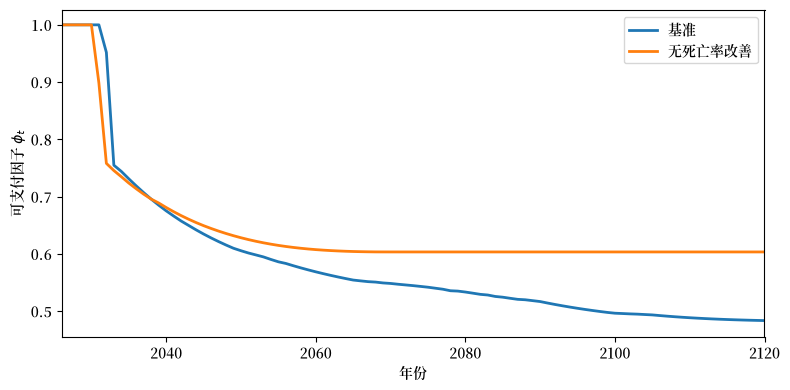

In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(YEARS, φ, lw=2, label='基准')
ax.plot(YEARS, flat['φ'], lw=2, label='无死亡率改善')
ax.set_xlabel('年份')
ax.set_ylabel('可支付因子 $\\phi_t$')
ax.set_xlim(Y0, 2120)
ax.legend()
plt.tight_layout()
plt.show()

寿命延长是长期问题的很大一部分原因。

在保持出生路径不变的情况下，它占到长期福利削减的约四分之一：可支付因子稳定在 $0.60$ 而不是 $0.48$。

耗竭年份几乎没有变动，原因在 {eq}`ssd_phi` 中清晰可见。

储备耗尽的日期由未来几年的现金流所决定，而这取决于已经活着的出生队列；死亡率改善的积累速度缓慢，到基金耗空时，它对成本率的大部分影响仍在数十年之后。

长期才是它们发挥作用的地方。

申领年龄稳定在 $65.0$ 而不是 $66.6$。

这正是本讲座为较晚申领所断言、但尚未加以验证的机制。

精算时间表 $\mathrm{AF}(\chi)$ 是法定且冻结的，因此当死亡率改善时，等待能在更多年份里获得更高的福利，于是工人选择等待。

关闭这种改善，这种推迟趋势就消失了。

```{solution-end}
```

```{exercise}
:label: ssd_ex5

{ref}`ssd_ex3` 从 $2026$ 年起保证支付计划福利，工人在 $2026$ 年得知此事，并从 $2026$ 年起纳税。

{cite:t}`SargentShi2026` 还研究了相反的时间安排，他们称之为**未预期的**情景。

政府什么都不说，什么都不做。

工人相信现行法律，针对他们所预期的削减制定计划并进行储蓄。

然后，在储备耗尽的那一年，政府宣布保证并立即提高融资税率。

工人原本预期的削减从未发生。

在这里重现该实验，并将其与 {ref}`ssd_ex3` 中的立即纾困进行比较。

1. 将基准经济向前推进到首个短缺年，并收集它在那一年所携带的状态：每个工人已积累的资产，以及它已经执行的退休和申领决策。
1. 使用 `solve_plans` 的 `at_year` 参数，让工人在那一年按 $\phi_t = 1$ 和工薪税率 $\tau^{*}$ 重新规划。
1. 为 $2026$ 年活着的工人对这三种经济进行估值，并报告每种纾困相对于耗竭基准的消费等价变化。谁更偏好这个意外情形？
```

```{solution-start} ssd_ex5
:class: dropdown
```

消费从工人最后一次重新规划的那一刻起即为 $c_0(\beta\tilde R)^{j-j_0}$，因此资产沿基准路径遵循一个单行的递归关系。

In [34]:
t_star = shortfall                       # 储备耗尽的那一年
j_star = np.clip(t_star - W.entry, 0, J-1)

c0_b = wealth_b/((1+par.τ_c)*Om_b)       # 基准计划，在2026年重新优化
m_b = income_path(W, φ, R_b, X_b)

a, A = np.zeros(W.C), np.zeros((J, W.C))
for j in range(J-1):
    a = np.where(j == W.j0, a26, a)      # 2026年截面数据在此进入
    A[j] = a
    surv = W.ell[:, j+1]/np.maximum(W.ell[:, j], 1e-12)
    c = c0_b*(par.β*after_tax_R(par))**np.maximum(j - W.j0, 0)
    a = np.where(j >= W.j0,
                 (after_tax_R(par)/np.maximum(surv, 1e-12))
                 * (a + m_b[j] - (1+par.τ_c)*c), 0.0)
A[J-1] = a
a_star = A[j_star, np.arange(W.C)]

old = W.entry == Y0 - 40                 # 2026年时60岁的出生队列
print(f"2026年时60岁的工人的资产: 2026年为{a26[old].mean():.2f}，"
      f" {t_star}年为{a_star[old].mean():.2f}")

2026年时60岁的工人的资产: 2026年为8.18， 2032年为9.25


现在是意外情形。

同一个 `solve_plans` 函数在 `t_star` 处重新规划，冻结其在此之前已经执行的决策。

In [35]:
R_n, X_n, wealth_n, Om_n, _ = solve_plans(
    W_bail, np.ones(T+1), j_star, plan0=(R_b, X_b),
    a0=a_star.reshape(W.C, 1), at_year=t_star)
c0_n = wealth_n/((1+par.τ_c)*Om_n)

R_i, X_i, wealth_i, Om_i, _ = solve_plans(          # 再次计算立即纾困
    W_bail, np.ones(T+1), W.j0, plan0=(R_pre, X_pre), a0=a26.reshape(W.C, 1))
c0_i = wealth_i/((1+par.τ_c)*Om_i)

我们直接对这三种经济进行估值，通过沿每个工人的实际消费和工作路径加总效用，而不是使用 {ref}`ssd_ex3` 的封闭形式。

In [36]:
ages_j = np.arange(J)
βR = par.β*after_tax_R(par)

def consumption(c0, j0, j_switch=None, c0_new=None):
    "每个年龄的消费，可选择在j_switch处重新规划。"
    c = c0[None, :]*βR**np.maximum(ages_j[:, None] - j0[None, :], 0)
    if j_switch is not None:
        c_new = c0_new[None, :]*βR**np.maximum(ages_j[:, None] - j_switch[None, :], 0)
        c = np.where(ages_j[:, None] >= j_switch[None, :], c_new, c)
    return c

def working(R, R_new=None, j_switch=None):
    w = (ages_j[:, None] < (R - AGE0)[None, :]).astype(float)
    if R_new is not None:
        w = np.where(ages_j[:, None] >= j_switch[None, :],
                     (ages_j[:, None] < (R_new - AGE0)[None, :]).astype(float), w)
    return w

def lifetime_value(W, c, work, j0):
    "Σ_{j≥j0} β^{j-j0} ℓ_{j|j0} [log c_j − η h n_j]，对每一行计算。"
    p = W.p
    wt = (p.β**ages_j)[:, None]*W.ell.T
    u = np.log(np.maximum(c, 1e-12)) - (p.η*W.η)[None, :]*work
    keep = ages_j[:, None] >= j0[None, :]
    return (np.where(keep, wt*u, 0.0).sum(axis=0)
            / ((p.β**j0)*W.ell[np.arange(W.C), j0]))

V_dep = lifetime_value(W, consumption(c0_b, W.j0), working(R_b), W.j0)
V_imm = lifetime_value(W, consumption(c0_i, W.j0), working(R_i), W.j0)
V_sur = lifetime_value(W, consumption(c0_b, W.j0, j_star, c0_n),
                       working(R_b, R_n, j_star), W.j0)

def cev_age(V1, V0, age):
    m = W.entry == Y0 - (age - AGE0)
    wts = W.w[m]/W.w[m].sum()
    return np.exp(((V1 - V0)[m]*wts).sum()/Om_b[m][0]) - 1

在查看答案之前，值得用一种不同的方法将这套机制与 {ref}`ssd_ex3` 的结果进行对照检验，后者计算立即纾困时使用了不同的方法。

In [37]:
print(f"{'2026年的年龄':>12}{'本练习':>15}{'练习3':>12}")
for a in (25, 45, 60, 80):
    print(f"{a:>12}{100*cev_age(V_imm, V_dep, a):>15.2f}"
          f"{100*λ_old[a-21]:>12.2f}")

    2026年的年龄            本练习         练习3
          25         -13.39      -13.39
          45          -6.18       -6.18
          60           6.54        6.54
          80           3.82        3.82


两者一致，因此我们可以比较这两种时间安排。

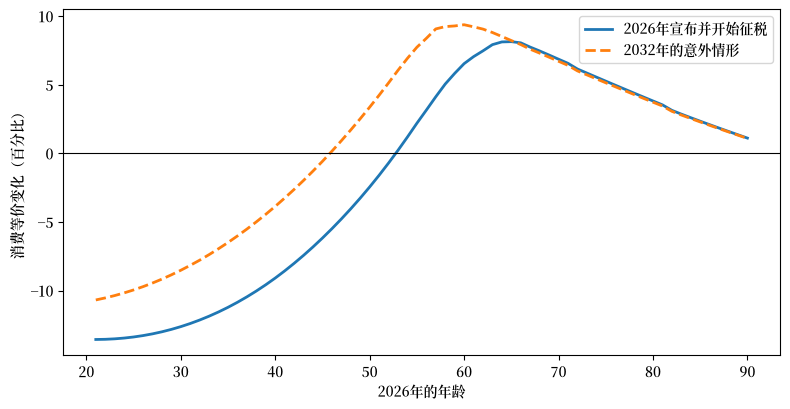

    2026年的年龄         立即        意外      收益
          25     -13.39     -9.96    3.43
          35     -11.22     -6.50    4.72
          45      -6.18     -0.58    5.59
          55       2.19      7.73    5.54
          65       8.14      8.22    0.08
          75       5.26      5.14   -0.12
          85       2.34      2.29   -0.05


In [38]:
ages_alive = np.arange(21, 91)
λ_imm = np.array([cev_age(V_imm, V_dep, a) for a in ages_alive])
λ_sur = np.array([cev_age(V_sur, V_dep, a) for a in ages_alive])

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(ages_alive, 100*λ_imm, lw=2, label='2026年宣布并开始征税')
ax.plot(ages_alive, 100*λ_sur, lw=2, ls='--', label=f'{t_star}年的意外情形')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('2026年的年龄')
ax.set_ylabel('消费等价变化（百分比）')
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'2026年的年龄':>12}{'立即':>11}{'意外':>10}{'收益':>8}")
for a in (25, 35, 45, 55, 65, 75, 85):
    i, u = 100*λ_imm[a-21], 100*λ_sur[a-21]
    print(f"{a:>12}{i:>11.2f}{u:>10.2f}{u-i:>8.2f}")

所有还有工作年限的人都偏好意外情形，而中年人尤其偏好它。

原因在于算术本身：两种经济最终都全额支付了每一份计划福利，而意外情形下少缴纳六年较高的税。

工人不再因该保证而受损的年龄从 $53$ 岁降至 $46$ 岁。

没有人真正受到削减，因为纾困恰好发生在储备耗尽的那一年，即本应发生首次全额削减的前一年。

收益在中年时期最大，$45$ 岁时为 $5.6$ 个百分点，因为此时还有许多年需要纳税，而退休又足够临近，使得误判计划所带来的代价不大。

对于年轻人来说，无论哪种时间安排，他们大部分人生都要缴纳更高的税率，因此收益较小。

对于七十多岁及以上、已经退休并已申领的工人来说，意外情形略微**更差**。

无论哪种时间安排，他们都不缴纳工薪税，因此延迟征税对他们没有任何好处，而他们白白为一种从未发生的削减多花了六年时间紧缩消费。

那些他们本可以享用却未享用的消费，是宣布本可以让他们免受的损失。

{cite:t}`SargentShi2026` 在工资税融资下发现了相同的排序，并增添了本模型所无法产生的一点：在一般均衡中，工人为一种从未到来的削减而积累的资产，*正是*纾困到来时该经济的资本存量，因此等待也会留下更高的工资水平。

而在这里，价格不变，全部收益都来自于推迟缴纳的税收。

```{solution-end}
```

```{exercise}
:label: ssd_ex6

本讲座的一切都建立在一次校准之上。

其中有两个数字值得做敏感性检验：人口统计目标，以及工人用以贴现的利率。

1. 将出生路径重新校准，使 $2085$ 年的老年赡养比分别为 $0.45$ 和 $0.55$，而非受托人的 $0.50$，并重新计算长期结果。
1. 在保持偏好参数为校准值的情况下，按 $5$ 个百分点和 $7$ 个百分点的利率重新计算。
1. 这两项变动中，哪一项改变了长期福利削减，哪一项改变了行为？使用 {eq}`ssd_longrun` 解释你的发现。
```

```{solution-start} ssd_ex6
:class: dropdown
```

每种情形都是一个全新的经济体：新的人口统计或新的价格都会改变消息传来之前制定的计划以及转型过程，因此我们重新求解两者。

这里二十五次阻尼迭代足以得到小数点后三位的精度。

In [39]:
def long_run(p, g, label):
    "端到端求解一个经济体，并报告其长期结果。"
    W_ = World(p, g)
    R0_, X0_, a0_, _, Ben0_, _, _ = pre_transition(W_)
    res = transition(W_, p.F_ratio*W_.Npop[0]*Ben0_[0], (R0_, X0_), a0_,
                     iters=25, verbose=False)
    mR_, mX_ = flow_ages(W_, res['R'], res['X'])
    print(f"{label:26}{YEARS[np.argmax(res['F'][:-1] <= 1e-12)]:>7}"
          f"{res['φ'][-1]:>8.3f}{(res['Ben']/res['Pay'])[-1]:>8.3f}"
          f"{res['Pay'][-1]:>9.3f}{res['Ben'][-1]:>10.4f}{mR_[-1]:>8.1f}")

print(f"{'':26}{'耗竭':>7}{'φ_∞':>8}{'成本':>8}{'工资':>9}{'福利':>10}{'退休':>8}")
long_run(par, g_pop, "基准")
for target in (0.45, 0.55):
    g_t = fsolve(lambda g: [dependency(g, 2025, par) - 0.32,
                            dependency(g, 2085, par) - target], [0.02, 0.0])
    long_run(par, g_t, f"2085年赡养比 = {target}")
for r_alt in (0.05, 0.07):
    long_run(par._replace(r=r_alt), g_pop, f"利率 = {r_alt}")

                               耗竭     φ_∞      成本       工资        福利      退休
基准                           2033   0.482   0.229    0.663    0.1519    65.3
2085年赡养比 = 0.45              2034   0.531   0.208    0.677    0.1408    64.9
2085年赡养比 = 0.55              2033   0.440   0.251    0.647    0.1622    65.5
利率 = 0.05                    2033   0.488   0.227    0.705    0.1597    68.5
利率 = 0.07                    2033   0.500   0.221    0.613    0.1355    62.0


基准                           2033   0.482   0.229    0.663    0.1519    65.3


2085年赡养比 = 0.45              2034   0.531   0.208    0.677    0.1408    64.9


2085年赡养比 = 0.55              2033   0.440   0.251    0.647    0.1622    65.5


利率 = 0.05                    2033   0.488   0.227    0.705    0.1597    68.5


利率 = 0.07                    2033   0.500   0.221    0.613    0.1355    62.0


人口统计移动了长期削减，而利率基本上没有移动它。

赡养比的五个百分点差异，相当于反方向约五个百分点的可支付因子差异。

利率使可支付因子移动一到两个百分点，同时使平均退休年龄移动了**六年半**，从利率为五个百分点时的 $68.5$ 岁到七个百分点时的 $62.0$ 岁。

方程 {eq}`ssd_longrun` 解释了原因。

长期削减仅通过成本率（即计划账单与应纳税工资总额之比）受行为影响，其旁边的两列显示了每个实验对分子和分母各自的影响。

更高的赡养比将两者推向相反的方向：缴税的工人更少，需支付的退休人员更多。

更高的利率将两者推向同一方向，且比例几乎相同：更短的职业生涯使应纳税工资总额缩水，而随之而来的更早申领买到的是更低的精算因子，因此计划账单也随之缩水。

这个比率几乎不受影响。

这正是福利公式的双时钟结构从长期（而非从转型过程）的视角呈现出来的样子：决定工人贡献多少的同一个职业决策，也决定了欠该工人多少，而在一个平稳经济体中，这两者几乎恰好相互抵消。

```{solution-end}
```